<a href="https://colab.research.google.com/github/laiajufresa-code/TFG/blob/main/TFG_llibreta1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cel·la 1: Càrrega

In [ ]:
import os, glob, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr
import kagglehub

warnings.filterwarnings("ignore")

path = kagglehub.dataset_download("colabsss/diabetes-risk-monitoring-dataset")
csv_path = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]
df_raw = pd.read_csv(csv_path)
print(df_raw.shape)
df_raw.head()

Using Colab cache for faster access to the 'diabetes-risk-monitoring-dataset' dataset.
(15000, 35)


,patient_id,monitoring_date,age,gender,bmi,family_history_diabetes,diabetes_duration_years,glucose_fasting_mg_dl,glucose_postprandial_mg_dl,hba1c_percent,...,stress_level_score,sensor_glucose_variability,heart_rate_variability_ms,daily_monitoring_frequency,abnormal_glucose_events,outpatient_visits_6m,medication_change_recent,comorbidity_count,previous_hypoglycemia_events,diabetes_risk_level
0,P00001,2024-01-01 00:00:00,56,Male,18.3,No,7.3,161.4,260.2,6.74,...,44.8,19.06,67.61,12,5,8,No,1,3,High_Risk
1,P00002,2024-01-01 01:00:00,69,Female,25.4,No,5.2,147.1,229.3,5.98,...,73.1,19.16,22.02,10,3,3,No,2,1,High_Risk
2,P00003,2024-01-01 02:00:00,46,Female,34.2,Yes,1.8,148.6,243.0,6.05,...,52.6,20.34,59.29,9,4,7,No,3,0,Moderate_Risk
3,P00004,2024-01-01 03:00:00,32,Male,31.9,Yes,4.9,122.7,185.1,5.65,...,75.9,16.49,59.04,20,2,3,No,1,2,Low_Risk
4,P00005,2024-01-01 04:00:00,60,Female,25.4,Yes,5.7,138.9,234.3,5.54,...,61.3,22.76,76.54,24,4,10,No,2,2,Low_Risk


Cel·la 2: Configuració i classificació de variables

In [ ]:
# ============ PARÀMETRES: es canvien NOMÉS aquí, la resta del codi s'adapta sol ============
CORRECCIO_NORMALITAT = None   # None = criteri (p > 0,05 sense corregir) · "holm" = amb correcció de Holm
FORMAT_TAULA1 = "per_grup"    # "per_grup" = normalitat avaluada a cada grup (com has demanat) · "per_variable" = mateix format a tota la fila
N_BOOT = 1000                 # rèpliques bootstrap per a l'IC de la mida d'efecte
SEED = 42
ALPHA = 0.05
assert CORRECCIO_NORMALITAT in (None, "holm") and FORMAT_TAULA1 in ("per_grup", "per_variable")
# ===========================================================================================

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "axes.labelsize": 10})

TARGET = "diabetes_risk_level"
ORDER  = ["Low_Risk", "Moderate_Risk", "High_Risk", "Critical_Risk"]
LABELS = {"Low_Risk": "Low", "Moderate_Risk": "Moderate", "High_Risk": "High", "Critical_Risk": "Critical"}
COLORS = {"Low_Risk": "#2ca02c", "Moderate_Risk": "#f2c94c", "High_Risk": "#f2994a", "Critical_Risk": "#d62728"}
ETIQ = [LABELS[o] for o in ORDER]
PAL4 = [COLORS[o] for o in ORDER]
CAT_PALETTE = ["#4C78A8", "#E45756"]

# --- Classificació de les 35 columnes ---
ID_COLS   = ["patient_id", "monitoring_date"]
CAT_BIN   = ["gender", "family_history_diabetes", "medication_change_recent"]       # categòriques binàries
DISC_COLS = ["comorbidity_count", "abnormal_glucose_events", "previous_hypoglycemia_events",
             "outpatient_visits_6m", "daily_monitoring_frequency"]                  # numèriques discretes
CONT_COLS = [c for c in df_raw.columns if c not in ID_COLS + CAT_BIN + DISC_COLS + [TARGET]]
NUM_COLS  = CONT_COLS + DISC_COLS         # van a correlació i a ANOVA/Kruskal
CATEG_COLS = CAT_BIN + DISC_COLS          # es mostren com a categòriques (gràfics de barres i n (%))

assert len(ID_COLS) + len(CAT_BIN) + len(DISC_COLS) + len(CONT_COLS) + 1 == df_raw.shape[1]
print(f"ID/data: {len(ID_COLS)} · categòriques binàries: {len(CAT_BIN)} · discretes: {len(DISC_COLS)} · "
      f"contínues: {len(CONT_COLS)} · objectiu: 1  (total {df_raw.shape[1]})")

# --- Dataset de treball: ID i data eliminats definitivament ---
df = df_raw.drop(columns=ID_COLS).copy()
df[TARGET] = pd.Categorical(df[TARGET], categories=ORDER, ordered=True)

# risk_num queda FORA de df: només per a correlacions i gràfics (mai com a variable d'un model)
risk_num = pd.Series(df[TARGET].cat.codes, index=df.index, name="risk_num")

def holm(p):
    """Correcció de Holm per a proves múltiples."""
    p = np.asarray(p, float); n = len(p); ordre = np.argsort(p)
    adj = np.empty(n); mx = 0.0
    for rang, i in enumerate(ordre):
        mx = max(mx, (n - rang) * p[i]); adj[i] = min(mx, 1.0)
    return adj

def fmt_p(p):
    """p-valor per a taules: '<0.001' en lloc de 0.0000."""
    return "<0.001" if p < 0.001 else f"{p:.3f}"

def amb_p(taula, cols):
    """Còpia d'una taula amb les columnes de p-valors formatades (els càlculs fan servir l'original)."""
    t = taula.copy()
    for c in cols:
        t[c] = t[c].map(fmt_p)
    return t

ID/data: 2 · categòriques binàries: 3 · discretes: 5 · contínues: 24 · objectiu: 1  (total 35)


Cel·la 3: Qualitat de dades

In [ ]:
# (df_raw només es fa servir aquí, per justificar l'exclusió de l'ID i la data; no es mostra cap ID)
print("Files, columnes:", df_raw.shape)
print("Valors nuls:", int(df_raw.isna().sum().sum()), "· files duplicades:", int(df_raw.duplicated().sum()))
print("ID únics:", df_raw["patient_id"].nunique(), "de", len(df_raw), "· dates úniques:", df_raw["monitoring_date"].nunique())

data = pd.to_datetime(df_raw["monitoring_date"])
print("Diferència entre dates consecutives:", data.diff().dropna().value_counts().to_dict())
rho, p = spearmanr(data.astype("int64"), risk_num)
print(f"Data vs risc (Spearman): rho = {rho:.3f}, p = {fmt_p(p)}")

# Registres amb una durada de diabetis superior a l'edat (impossible); es mostren pel número de fila
imp = df["diabetes_duration_years"] > df["age"]
imp_idx = df.index[imp]
print(f"\nRegistres amb durada de diabetis > edat: {imp.sum()}")
display(df.loc[imp, ["age", "diabetes_duration_years", TARGET]])

# Valors acumulats exactament al mínim o al màxim (dades "tallades")
rows = []
for c in NUM_COLS:
    mn, mx = df[c].min(), df[c].max()
    rows.append({"variable": c, "mínim": mn, "% al mínim": round((df[c] == mn).mean() * 100, 2),
                 "màxim": mx, "% al màxim": round((df[c] == mx).mean() * 100, 2)})
tall = pd.DataFrame(rows).set_index("variable")
display(tall[(tall["% al mínim"] > 0.5) | (tall["% al màxim"] > 0.5)])

Files, columnes: (15000, 35)
Valors nuls: 0 · files duplicades: 0
ID únics: 15000 de 15000 · dates úniques: 15000
Diferència entre dates consecutives: {Timedelta('0 days 01:00:00'): 14999}
Data vs risc (Spearman): rho = -0.011, p = 0.193

Registres amb durada de diabetis > edat: 3


,age,diabetes_duration_years,diabetes_risk_level
2416,23,23.7,Critical_Risk
6512,20,21.1,Critical_Risk
6662,18,19.6,High_Risk


,mínim,% al mínim,màxim,% al màxim
variable,,,,
age,18.0,1.52,80.0,1.57
bmi,17.5,2.01,42.0,0.11
physical_activity_min,5.0,1.74,134.0,0.01
step_count,500.0,3.68,13080.0,0.01
sleep_quality_score,38.4,0.01,100.0,0.67
medication_adherence_pct,53.6,0.01,100.0,10.83
insulin_dose_units,0.0,8.64,59.9,0.01
heart_rate_variability_ms,15.0,0.53,100.3,0.01
comorbidity_count,0.0,34.33,6.0,0.15


\Cel·la 4 · Distribució de la classe objectiu

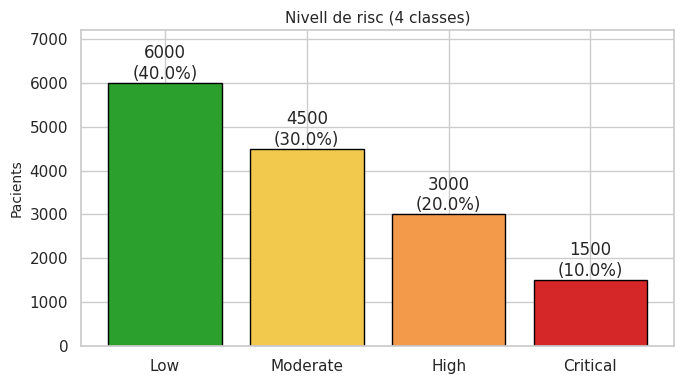

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
cnt = df[TARGET].value_counts().reindex(ORDER)
bars = ax.bar(ETIQ, cnt.values, color=PAL4, edgecolor="black")
for b, v in zip(bars, cnt.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v / len(df):.1%})", ha="center", va="bottom")
ax.set_title("Nivell de risc (4 classes)"); ax.set_ylabel("Pacients"); ax.set_ylim(0, cnt.max() * 1.2)
plt.tight_layout(); plt.show()

Cel·la 5 · Normalitat per variable i grup

In [ ]:
# Normalitat INDIVIDUAL de cada variable contínua dins de cada grup de risc (D'Agostino-Pearson)
p_norm = pd.DataFrame({LABELS[o]: [stats.normaltest(df.loc[df[TARGET] == o, c])[1] for c in CONT_COLS]
                       for o in ORDER}, index=CONT_COLS)
p_norm_holm = pd.DataFrame(holm(p_norm.values.ravel()).reshape(p_norm.shape),
                           index=p_norm.index, columns=p_norm.columns)       # mateixos tests, corregits (96)

p_usat = p_norm_holm if CORRECCIO_NORMALITAT == "holm" else p_norm          # el que decideix, segons el paràmetre
es_normal = p_usat > ALPHA                                                  # True/False per variable i grup
normal_4 = es_normal.all(axis=1)                                            # normal als 4 grups -> ANOVA

norm = p_norm.add_prefix("p_")
norm["grups_normals"] = es_normal.sum(axis=1)
norm["normal_en_4_classes"] = normal_4
norm["normal_sense_correccio"] = (p_norm > ALPHA).all(axis=1)
norm["normal_amb_Holm"] = (p_norm_holm > ALPHA).all(axis=1)
norm["max_|asimetria|"] = [max(abs(df.loc[df[TARGET] == o, c].skew()) for o in ORDER) for c in CONT_COLS]
norm["max_|curtosi|"]   = [max(abs(df.loc[df[TARGET] == o, c].kurt()) for o in ORDER) for c in CONT_COLS]

display(amb_p(norm, [c for c in norm.columns if c.startswith("p_")]).round(3))
print("Criteri en ús:", "Holm" if CORRECCIO_NORMALITAT == "holm" else "sense correcció (tutora)")
print("Variables normals als 4 grups: sense correcció =", int(norm["normal_sense_correccio"].sum()),
      "· amb Holm =", int(norm["normal_amb_Holm"].sum()), "(de", len(norm), ")")
print("Variables amb grups mixtos (alguns grups normals i altres no):",
      int(((norm["grups_normals"] > 0) & (~norm["normal_en_4_classes"])).sum()))

,p_Low,p_Moderate,p_High,p_Critical,grups_normals,normal_en_4_classes,normal_sense_correccio,normal_amb_Holm,max_|asimetria|,max_|curtosi|
age,<0.001,<0.001,<0.001,<0.001,0,False,False,False,1.048,1.055
bmi,<0.001,<0.001,0.003,0.016,0,False,False,False,0.146,0.311
diabetes_duration_years,<0.001,<0.001,<0.001,<0.001,0,False,False,False,0.987,1.151
glucose_fasting_mg_dl,0.029,0.809,0.885,0.022,2,False,False,True,0.174,0.046
glucose_postprandial_mg_dl,0.024,0.457,0.258,0.503,3,False,False,True,0.072,0.144
hba1c_percent,0.019,0.838,0.922,<0.001,2,False,False,False,0.274,0.288
heart_rate_bpm,0.171,0.281,0.354,0.256,4,True,True,True,0.062,0.174
systolic_bp_mmhg,<0.001,0.034,0.002,0.076,1,False,False,False,0.121,0.236
diastolic_bp_mmhg,0.059,0.066,0.866,0.799,4,True,True,True,0.077,0.079
spo2_percent,0.663,0.922,0.761,0.943,4,True,True,True,0.032,0.054


Criteri en ús: sense correcció (tutora)
Variables normals als 4 grups: sense correcció = 8 · amb Holm = 14 (de 24 )
Variables amb grups mixtos (alguns grups normals i altres no): 8


Cel·la 6 · Tests globals i mida d’efecte

In [ ]:
def dunn_bonferroni(grups, etiquetes):
    """Post-hoc de Dunn amb correcció de Bonferroni (per a Kruskal-Wallis)."""
    valors = np.concatenate(grups); N = len(valors)
    rangs = stats.rankdata(valors)
    _, t = np.unique(valors, return_counts=True)
    correccio_empats = (t**3 - t).sum()
    limits = np.cumsum([0] + [len(g) for g in grups])
    rang_mitja = [rangs[limits[i]:limits[i + 1]].mean() for i in range(len(grups))]
    parelles = list(itertools.combinations(range(len(grups)), 2))
    out = []
    for i, j in parelles:
        var = (N * (N + 1) / 12 - correccio_empats / (12 * (N - 1))) * (1 / len(grups[i]) + 1 / len(grups[j]))
        z = (rang_mitja[i] - rang_mitja[j]) / np.sqrt(var)
        out.append((f"{etiquetes[i]} vs {etiquetes[j]}", min(2 * stats.norm.sf(abs(z)) * len(parelles), 1.0)))
    return out

def classifica(e):
    """Field (2013), també usat per a epsilon² al paquet effectsize: <0,01 molt petit · <0,06 petit · <0,14 mitjà · >=0,14 gran."""
    return "gran" if e >= 0.14 else "mitjà" if e >= 0.06 else "petit" if e >= 0.01 else "molt petit"

rows = []
for col in NUM_COLS:
    g = [df.loc[df[TARGET] == o, col].values for o in ORDER]
    N, k = sum(len(x) for x in g), len(g)
    H, p_kw = stats.kruskal(*g)
    eps2 = (H - k + 1) / (N - k)                    # mida d'efecte comparable per a TOTES les variables
    lev = stats.levene(*g)[1]
    if (col in CONT_COLS) and bool(normal_4.loc[col]):
        test, estad, p = "ANOVA", *stats.f_oneway(*g)
        tot = np.concatenate(g); gm = tot.mean()
        eta2 = sum(len(x) * (x.mean() - gm) ** 2 for x in g) / ((tot - gm) ** 2).sum()
    else:
        test, estad, p, eta2 = "Kruskal-Wallis", H, p_kw, np.nan
    rows.append({"variable": col, "tipus": "discreta" if col in DISC_COLS else "contínua",
                 "test": test, "estadístic": estad, "p": p, "eps2_rangs": eps2, "eta2_anova": eta2,
                 "levene_p": lev})
res = pd.DataFrame(rows).set_index("variable")
res["p_holm"] = holm(res["p"])
res["significatiu"] = res["p_holm"] < ALPHA
res["efecte"] = res["eps2_rangs"].apply(classifica)

display(amb_p(res, ["p", "p_holm", "levene_p"]).sort_values("eps2_rangs", ascending=False).round(4))
print(res["test"].value_counts().to_string())
print("Sense diferències significatives (Holm):", list(res.index[~res["significatiu"]]))
print("ANOVA amb variàncies diferents (Levene p<0,05):",
      list(res.index[(res["test"] == "ANOVA") & (res["levene_p"] < ALPHA)]))

,tipus,test,estadístic,p,eps2_rangs,eta2_anova,levene_p,p_holm,significatiu,efecte
variable,,,,,,,,,,
glucose_fasting_mg_dl,contínua,Kruskal-Wallis,7859.0155,<0.001,0.5239,NaN,<0.001,<0.001,True,gran
hba1c_percent,contínua,Kruskal-Wallis,7534.0953,<0.001,0.5022,NaN,<0.001,<0.001,True,gran
glucose_postprandial_mg_dl,contínua,Kruskal-Wallis,4924.2627,<0.001,0.3282,NaN,<0.001,<0.001,True,gran
insulin_dose_units,contínua,Kruskal-Wallis,3495.1433,<0.001,0.2329,NaN,<0.001,<0.001,True,gran
age,contínua,Kruskal-Wallis,3261.3745,<0.001,0.2173,NaN,<0.001,<0.001,True,gran
diabetes_duration_years,contínua,Kruskal-Wallis,3148.2428,<0.001,0.2097,NaN,<0.001,<0.001,True,gran
abnormal_glucose_events,discreta,Kruskal-Wallis,2875.5028,<0.001,0.1916,NaN,0.152,<0.001,True,gran
comorbidity_count,discreta,Kruskal-Wallis,2663.1619,<0.001,0.1774,NaN,<0.001,<0.001,True,gran
systolic_bp_mmhg,contínua,Kruskal-Wallis,2010.4198,<0.001,0.1339,NaN,0.022,<0.001,True,mitjà


test
Kruskal-Wallis    21
ANOVA              8
Sense diferències significatives (Holm): ['body_temperature_c', 'water_intake_l', 'outpatient_visits_6m', 'daily_monitoring_frequency']
ANOVA amb variàncies diferents (Levene p<0,05): ['body_temperature_c']


Cel·la 7 · Post-hoc

In [ ]:
posthoc = {}
for col in res.index[res["significatiu"]]:
    g = [df.loc[df[TARGET] == o, col].values for o in ORDER]
    if res.loc[col, "test"] == "ANOVA":
        tk = stats.tukey_hsd(*g)
        posthoc[col] = [(f"{ETIQ[i]} vs {ETIQ[j]}", tk.pvalue[i, j]) for i, j in itertools.combinations(range(4), 2)]
    else:
        posthoc[col] = dunn_bonferroni(g, ETIQ)

def estrelles(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"

parelles_noms = [f"{ETIQ[i]} vs {ETIQ[j]}" for i, j in itertools.combinations(range(4), 2)]
taula = pd.DataFrame("—", index=NUM_COLS, columns=parelles_noms)
for col, llista in posthoc.items():
    for nom, p in llista:
        taula.loc[col, nom] = estrelles(p)
taula.insert(0, "test", res["test"])

def color(v):
    if v in ("***", "**", "*"): return "background-color:#c8e6c9"
    if v == "ns": return "background-color:#ffcdd2"
    return ""
display(taula.style.map(color, subset=parelles_noms))

,test,Low vs Moderate,Low vs High,Low vs Critical,Moderate vs High,Moderate vs Critical,High vs Critical
age,Kruskal-Wallis,***,***,***,***,***,***
bmi,Kruskal-Wallis,***,***,***,***,***,***
diabetes_duration_years,Kruskal-Wallis,***,***,***,***,***,***
glucose_fasting_mg_dl,Kruskal-Wallis,***,***,***,***,***,***
glucose_postprandial_mg_dl,Kruskal-Wallis,***,***,***,***,***,***
hba1c_percent,Kruskal-Wallis,***,***,***,***,***,***
heart_rate_bpm,ANOVA,***,***,***,**,***,*
systolic_bp_mmhg,Kruskal-Wallis,***,***,***,***,***,***
diastolic_bp_mmhg,ANOVA,***,***,***,***,***,**
spo2_percent,ANOVA,***,***,***,***,***,*


:Cel·la 8 · Khi quadrat de les 3 binàries

In [ ]:
rows = []
for col in CAT_BIN:
    ct = pd.crosstab(df[col], df[TARGET])
    chi, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi / (len(df) * (min(ct.shape) - 1)))
    rows.append({"variable": col, "khi2": chi, "gl": dof, "p": p, "V_Cramér": v})
chi_res = pd.DataFrame(rows).set_index("variable")
chi_res["p_holm"] = holm(chi_res["p"])
display(amb_p(chi_res, ["p", "p_holm"]).round(4))

,khi2,gl,p,V_Cramér,p_holm
variable,,,,,
gender,2.1782,3,0.536,0.0121,1.000
family_history_diabetes,0.9748,3,0.807,0.0081,1.000
medication_change_recent,0.0171,3,0.999,0.0011,1.000


Cel·la 9 · Taula 1 (contínues per grup)

In [ ]:
def cel_la_cont(x, normal):
    """Normal -> Mean ± SD / 95% CI.  No normal -> Median (IQR) / Mínim - Màxim."""
    if normal:
        n, m, sd = len(x), x.mean(), x.std()
        lo, hi = stats.t.interval(0.95, n - 1, loc=m, scale=sd / np.sqrt(n))
        return f"{m:.2f} ± {sd:.2f}\n95% CI ({lo:.2f} - {hi:.2f})"
    q1, med, q3 = x.quantile([.25, .5, .75])
    return f"{med:.2f} ({q1:.2f}-{q3:.2f})\n{x.min():.2f} - {x.max():.2f}"

def es_normal_cel_la(c, o):
    return bool(es_normal.loc[c, LABELS[o]]) if FORMAT_TAULA1 == "per_grup" else bool(normal_4.loc[c])

n_grup = {o: int((df[TARGET] == o).sum()) for o in ORDER}
t1_cont = pd.DataFrame(
    {f"{LABELS[o]} (n={n_grup[o]})": [cel_la_cont(df.loc[df[TARGET] == o, c], es_normal_cel_la(c, o))
                                       for c in CONT_COLS] for o in ORDER},
    index=CONT_COLS)
t1_cont["Test"] = res.loc[CONT_COLS, "test"]
t1_cont["p (Holm)"] = res.loc[CONT_COLS, "p_holm"].map(fmt_p)
t1_cont["Efecte (ε²)"] = [f"{res.loc[c, 'eps2_rangs']:.3f} ({res.loc[c, 'efecte']})" for c in CONT_COLS]

print("TAULA 1 · Variables contínues per grup de risc  [format:", FORMAT_TAULA1, "]")
print("Grup NORMAL      -> línia 1: Mean ± SD | línia 2: 95% CI (límit inferior - límit superior)")
print("Grup NO NORMAL   -> línia 1: Median (Q1-Q3) | línia 2: Mínim - Màxim\n")
display(t1_cont.style.set_properties(**{"white-space": "pre-line", "text-align": "center"}))


TAULA 1 · Variables contínues per grup de risc  [format: per_grup ]
Grup NORMAL      -> línia 1: Mean ± SD | línia 2: 95% CI (límit inferior - límit superior)
Grup NO NORMAL   -> línia 1: Median (Q1-Q3) | línia 2: Mínim - Màxim



,Low (n=6000),Moderate (n=4500),High (n=3000),Critical (n=1500),Test,p (Holm),Efecte (ε²)
age,37.00 (27.00-50.00) 18.00 - 80.00,52.00 (37.00-66.00) 18.00 - 80.00,61.00 (46.00-72.00) 18.00 - 80.00,67.00 (55.00-75.00) 18.00 - 80.00,Kruskal-Wallis,<0.001,0.217 (gran)
bmi,26.30 (23.20-29.50) 17.50 - 42.00,27.20 (24.18-30.30) 17.50 - 42.00,28.20 (25.00-31.40) 17.50 - 42.00,28.90 (25.48-32.20) 17.50 - 42.00,Kruskal-Wallis,<0.001,0.033 (petit)
diabetes_duration_years,3.40 (2.10-5.00) 0.00 - 15.90,4.60 (3.00-6.80) 0.20 - 21.40,6.10 (3.90-8.40) 0.20 - 20.70,8.90 (6.20-12.20) 0.40 - 25.00,Kruskal-Wallis,<0.001,0.210 (gran)
glucose_fasting_mg_dl,126.30 (116.78-135.80) 70.50 - 172.80,142.42 ± 12.50 95% CI (142.06 - 142.79),153.97 ± 12.70 95% CI (153.51 - 154.42),166.90 (157.90-176.70) 130.10 - 215.20,Kruskal-Wallis,<0.001,0.524 (gran)
glucose_postprandial_mg_dl,186.50 (165.47-207.00) 95.00 - 290.10,210.38 ± 28.61 95% CI (209.54 - 211.21),227.47 ± 27.98 95% CI (226.47 - 228.47),248.58 ± 30.25 95% CI (247.05 - 250.11),Kruskal-Wallis,<0.001,0.328 (gran)
hba1c_percent,5.64 (5.32-5.95) 4.20 - 7.31,6.12 ± 0.42 95% CI (6.11 - 6.14),6.49 ± 0.42 95% CI (6.48 - 6.51),6.96 (6.68-7.28) 5.71 - 8.66,Kruskal-Wallis,<0.001,0.502 (gran)
heart_rate_bpm,74.69 ± 7.21 95% CI (74.51 - 74.87),75.61 ± 7.25 95% CI (75.40 - 75.82),76.18 ± 6.98 95% CI (75.93 - 76.43),76.78 ± 6.95 95% CI (76.42 - 77.13),ANOVA,<0.001,0.009 (molt petit)
systolic_bp_mmhg,132.50 (124.00-141.00) 94.10 - 174.80,139.50 (130.50-148.00) 95.90 - 182.10,143.60 (134.30-151.70) 94.40 - 183.90,146.38 ± 12.11 95% CI (145.77 - 146.99),Kruskal-Wallis,<0.001,0.134 (mitjà)
diastolic_bp_mmhg,73.40 ± 6.68 95% CI (73.23 - 73.57),75.58 ± 6.67 95% CI (75.39 - 75.78),77.30 ± 6.65 95% CI (77.06 - 77.54),78.00 ± 6.74 95% CI (77.66 - 78.34),ANOVA,<0.001,0.062 (mitjà)
spo2_percent,97.73 ± 0.72 95% CI (97.71 - 97.75),97.59 ± 0.73 95% CI (97.57 - 97.61),97.52 ± 0.73 95% CI (97.50 - 97.55),97.46 ± 0.72 95% CI (97.42 - 97.50),ANOVA,<0.001,0.017 (petit)


Cel·la 10 · Taula 2 (categòriques i discretes)

In [ ]:
files = []
for c in CATEG_COLS:
    for cat in sorted(df[c].unique()):
        fila = {"variable": c, "categoria": cat}
        for o in ORDER:
            sub = df.loc[df[TARGET] == o, c]
            n = int((sub == cat).sum())
            fila[f"{LABELS[o]} (n={len(sub)})"] = f"{n} ({n / len(sub) * 100:.1f}%)"
        files.append(fila)
t1_cat = pd.DataFrame(files).set_index(["variable", "categoria"])
t1_cat["Test"] = ""
t1_cat["p (Holm)"] = ""
for c in CATEG_COLS:                                         # test i p-valor a la primera fila de cada variable
    primera = t1_cat.loc[c].index[0]
    t1_cat.loc[(c, primera), "Test"] = "Khi quadrat" if c in CAT_BIN else "Kruskal-Wallis"
    t1_cat.loc[(c, primera), "p (Holm)"] = fmt_p(chi_res.loc[c, "p_holm"] if c in CAT_BIN else res.loc[c, "p_holm"])

print("TAULA 2 · Variables categòriques per grup de risc: n (% dins del grup)")
display(t1_cat)


TAULA 2 · Variables categòriques per grup de risc: n (% dins del grup)


Low (n=6000) Moderate (n=4500)  \
variable                   categoria                                   
gender                     Female     2940 (49.0%)      2163 (48.1%)   
                           Male       3060 (51.0%)      2337 (51.9%)   
family_history_diabetes    No         3758 (62.6%)      2843 (63.2%)   
                           Yes        2242 (37.4%)      1657 (36.8%)   
medication_change_recent   No         4653 (77.5%)      3487 (77.5%)   
...                                            ...               ...   
daily_monitoring_frequency 20           263 (4.4%)        213 (4.7%)   
                           21           296 (4.9%)        219 (4.9%)   
                           22           296 (4.9%)        202 (4.5%)   
                           23           291 (4.9%)        207 (4.6%)   
                           24           296 (4.9%)        194 (4.3%)   

                                     High (n=3000) Critical (n=1500)  \
variable                   categoria                                   
gender                     Female     1493 (49.8%)       735 (49.0%)   
                           Male       1507 (50.2%)       765 (51.0%)   
family_history_diabetes    No         1879 (62.6%)       927 (61.8%)   
                           Yes        1121 (37.4%)       573 (38.2%)   
medication_change_recent   No         2325 (77.5%)      1161 (77.4%)   
...                                            ...               ...   
daily_monitoring_frequency 20           120 (4.0%)         81 (5.4%)   
                           21           140 (4.7%)         67 (4.5%)   
                           22           149 (5.0%)         72 (4.8%)   
                           23           151 (5.0%)         88 (5.9%)   
                           24           142 (4.7%)         74 (4.9%)   

                                             Test p (Holm)  
variable                   categoria                        
gender                     Female     Khi quadrat    1.000  
                           Male                             
family_history_diabetes    No         Khi quadrat    1.000  
                           Yes                              
medication_change_recent   No         Khi quadrat    1.000  
...                                           ...      ...  
daily_monitoring_frequency 20                               
                           21                               
                           22                               
                           23                               
                           24                               

[69 rows x 6 columns]

Cel·la 11 · Gràfics de les contínues

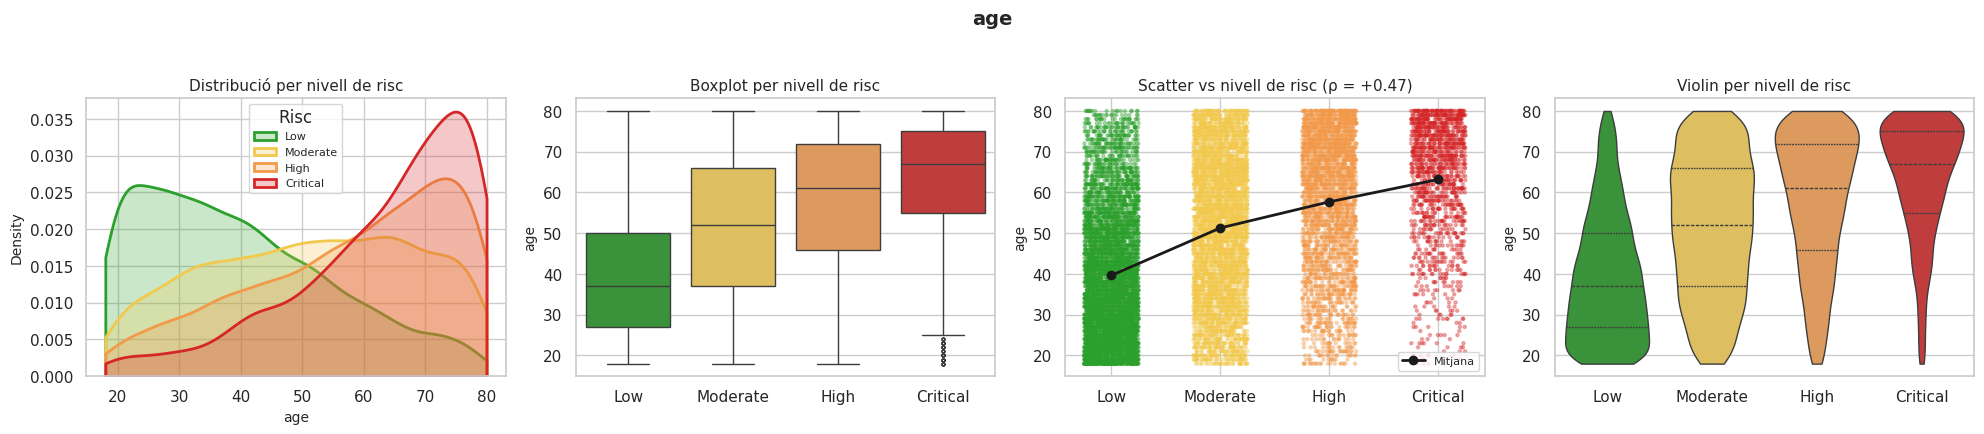

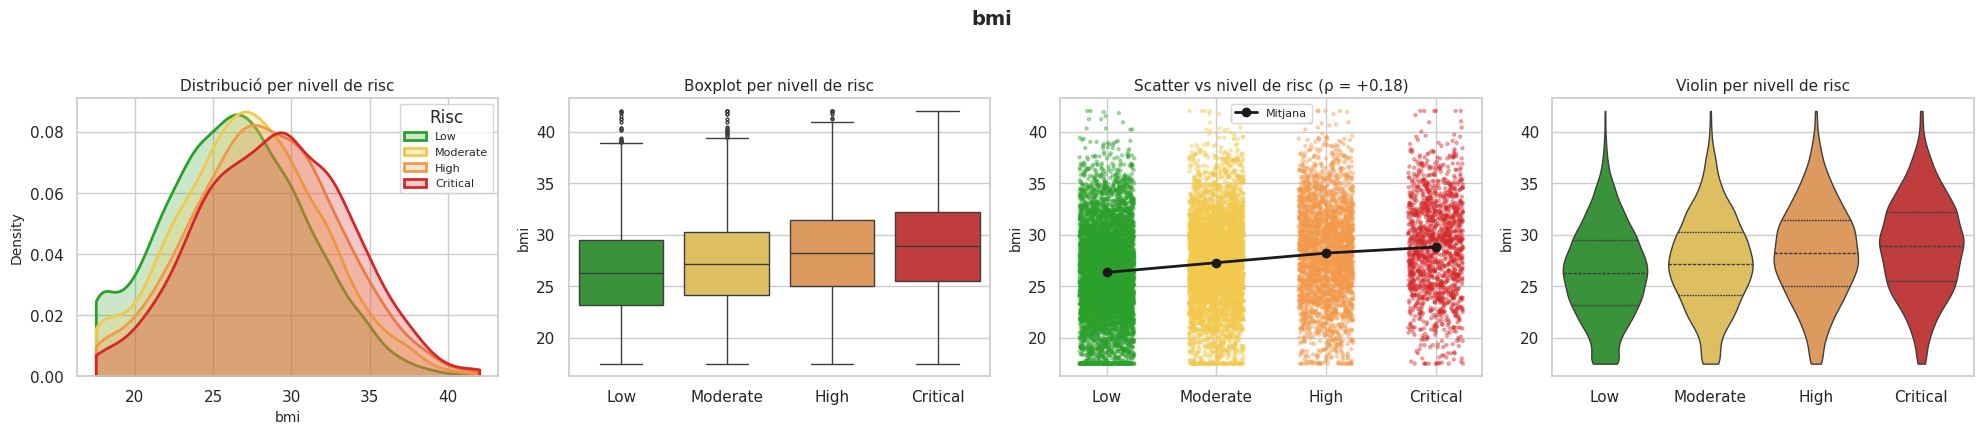

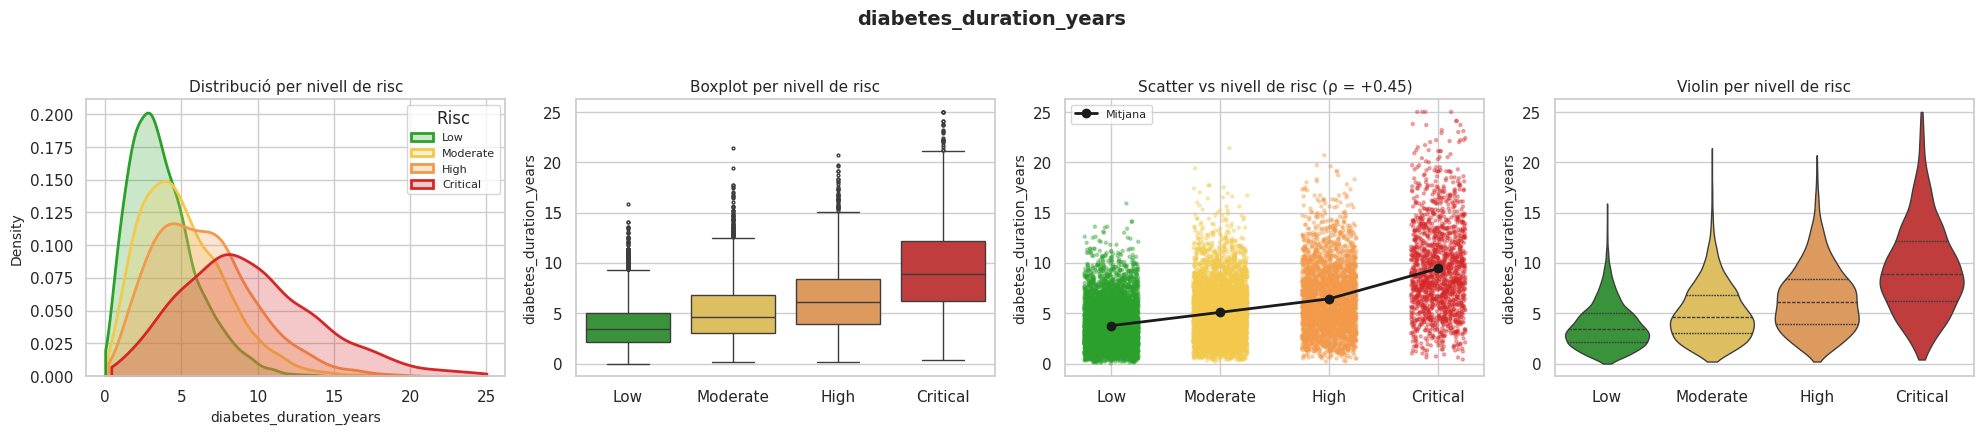

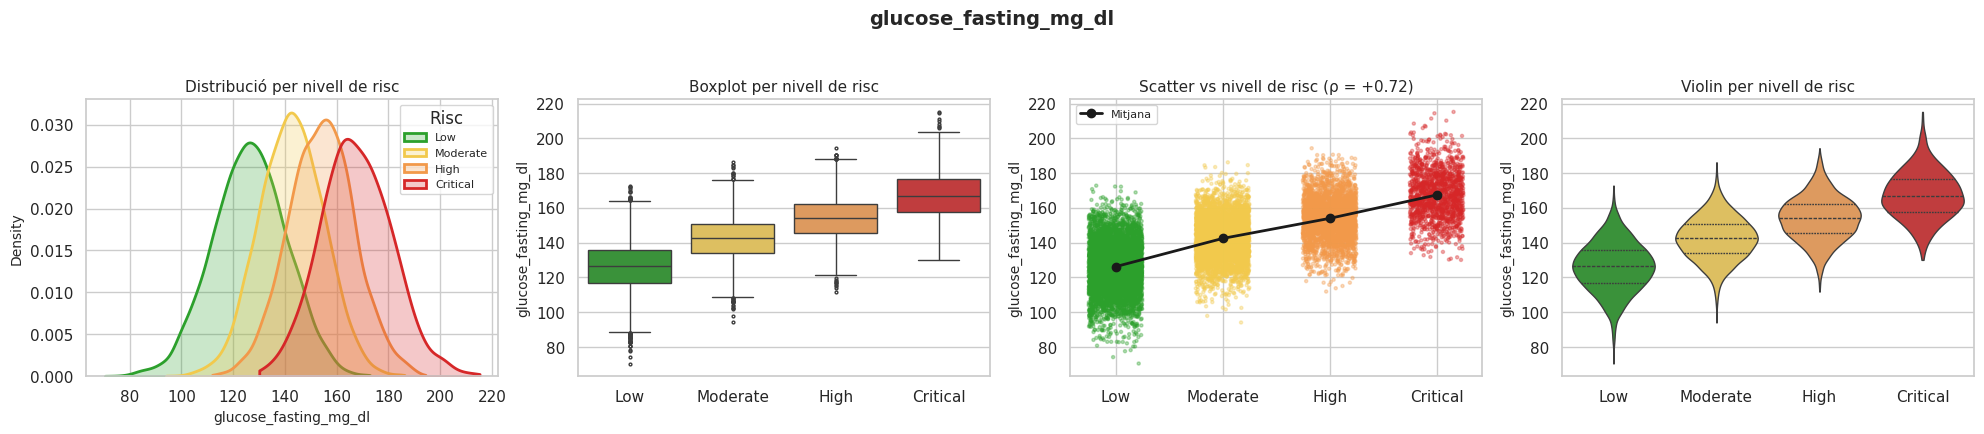

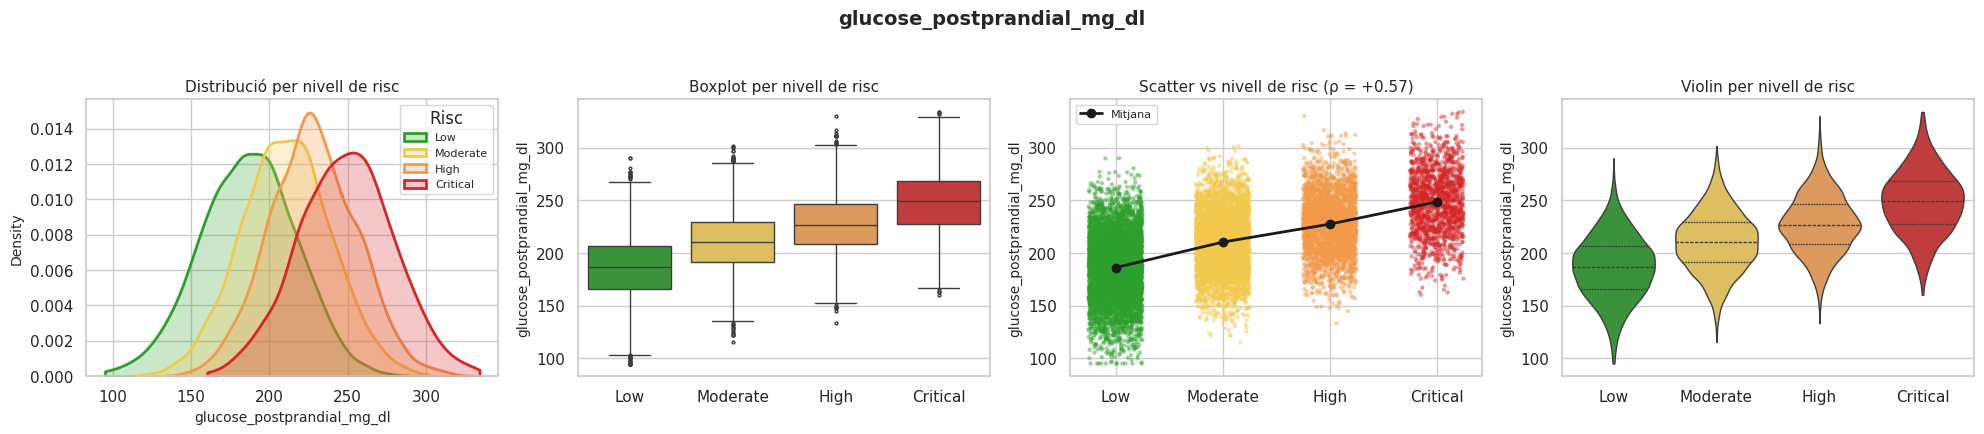

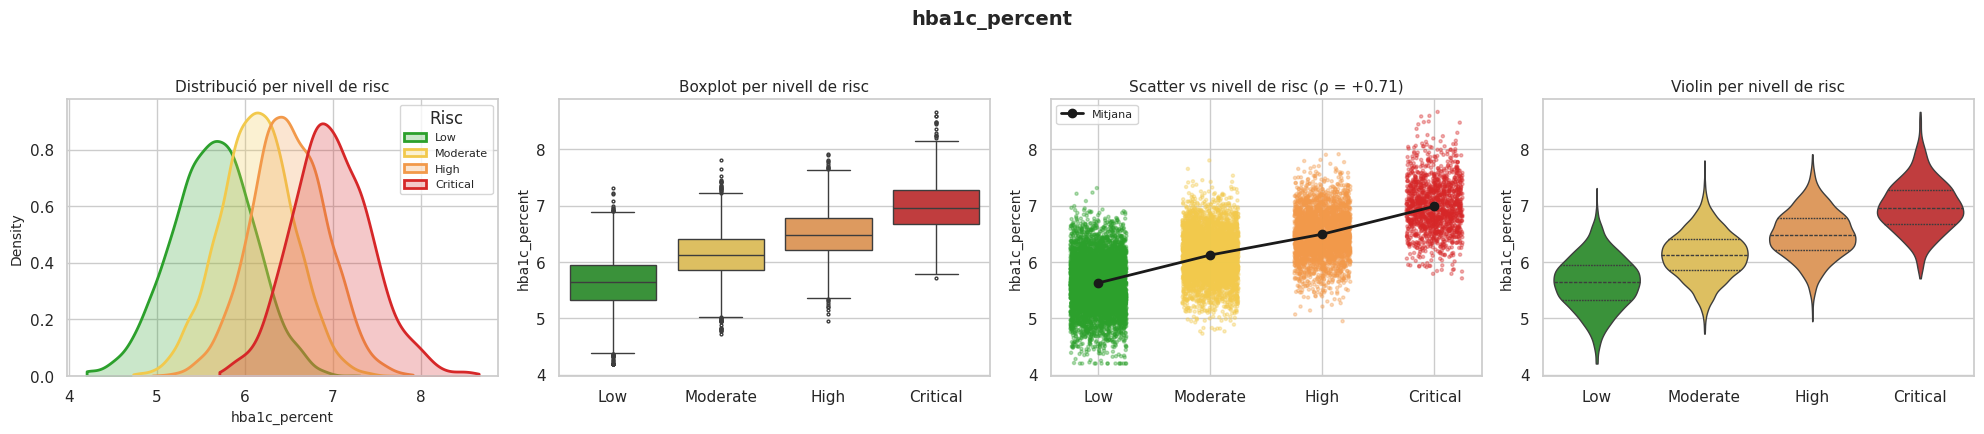

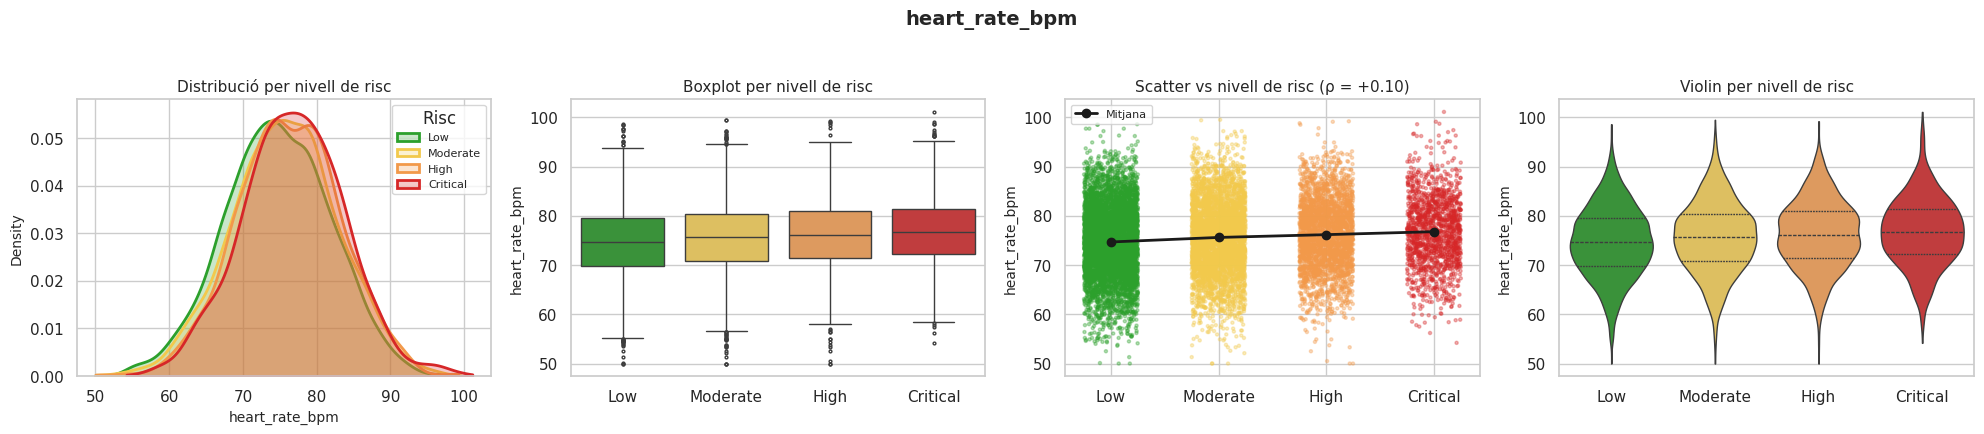

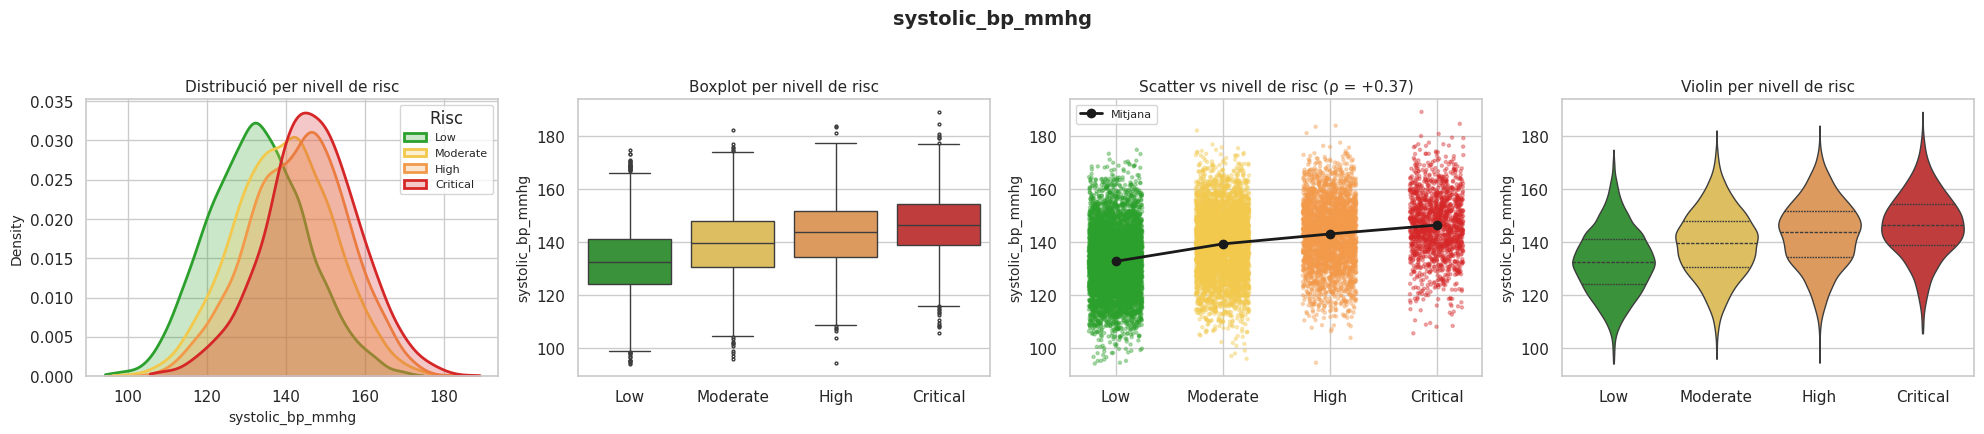

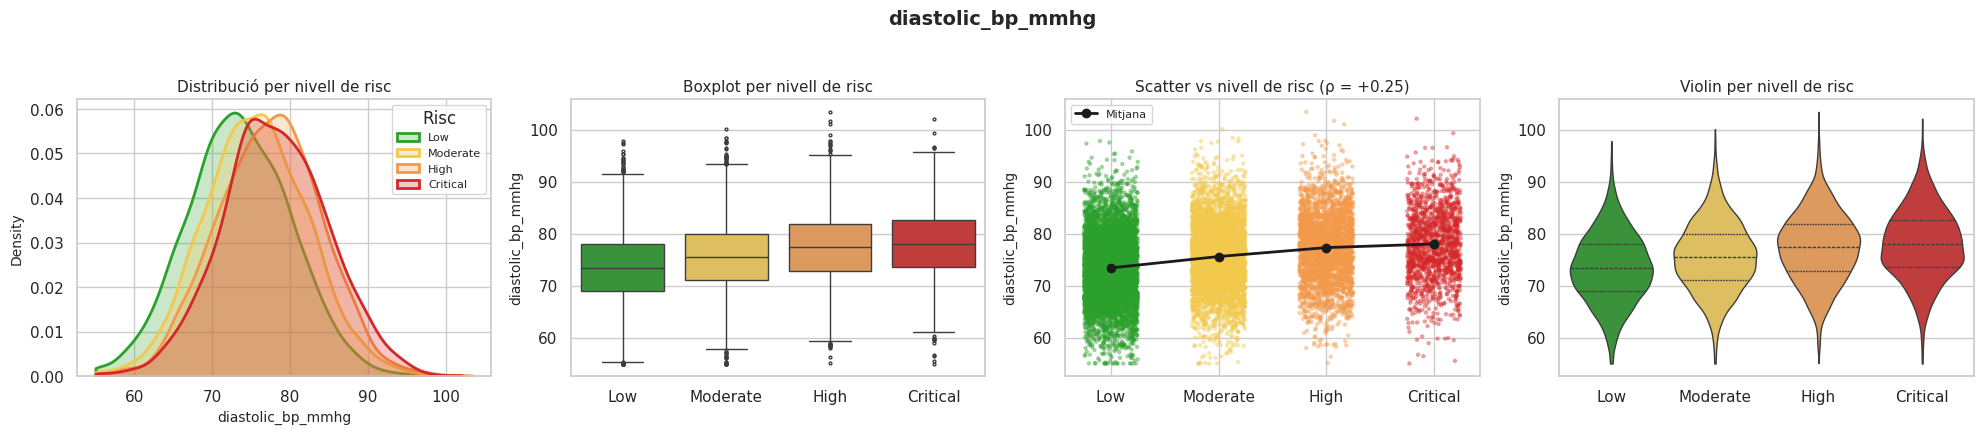

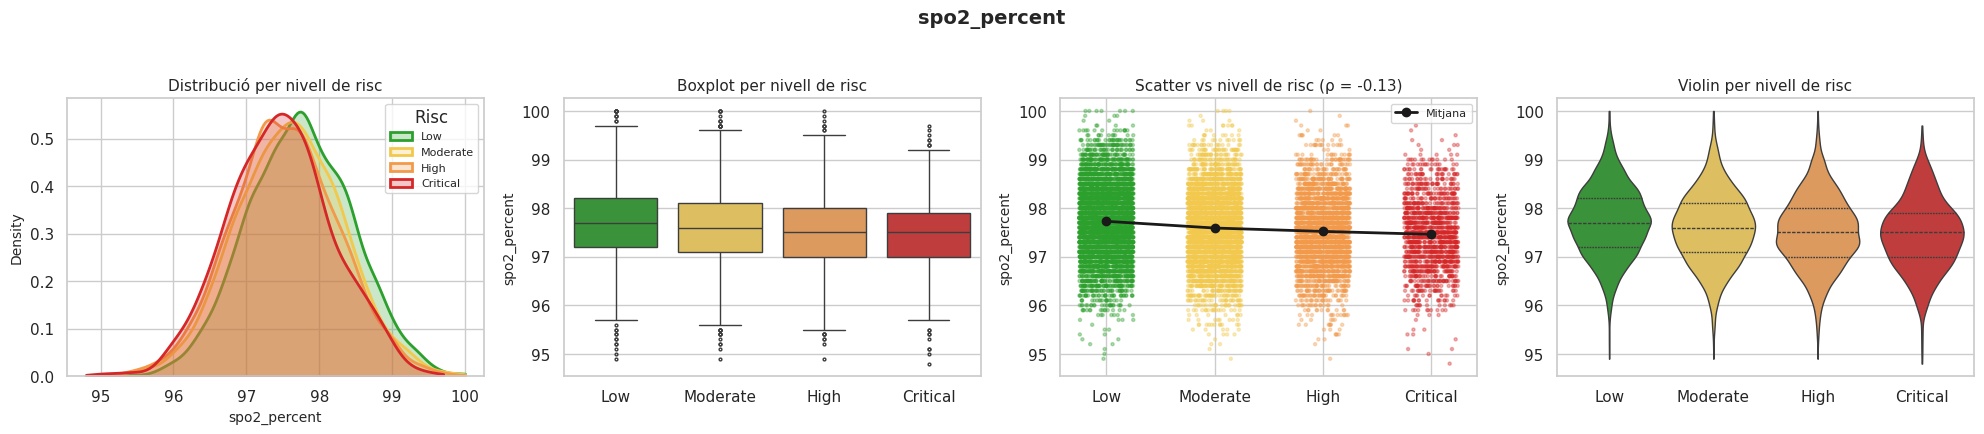

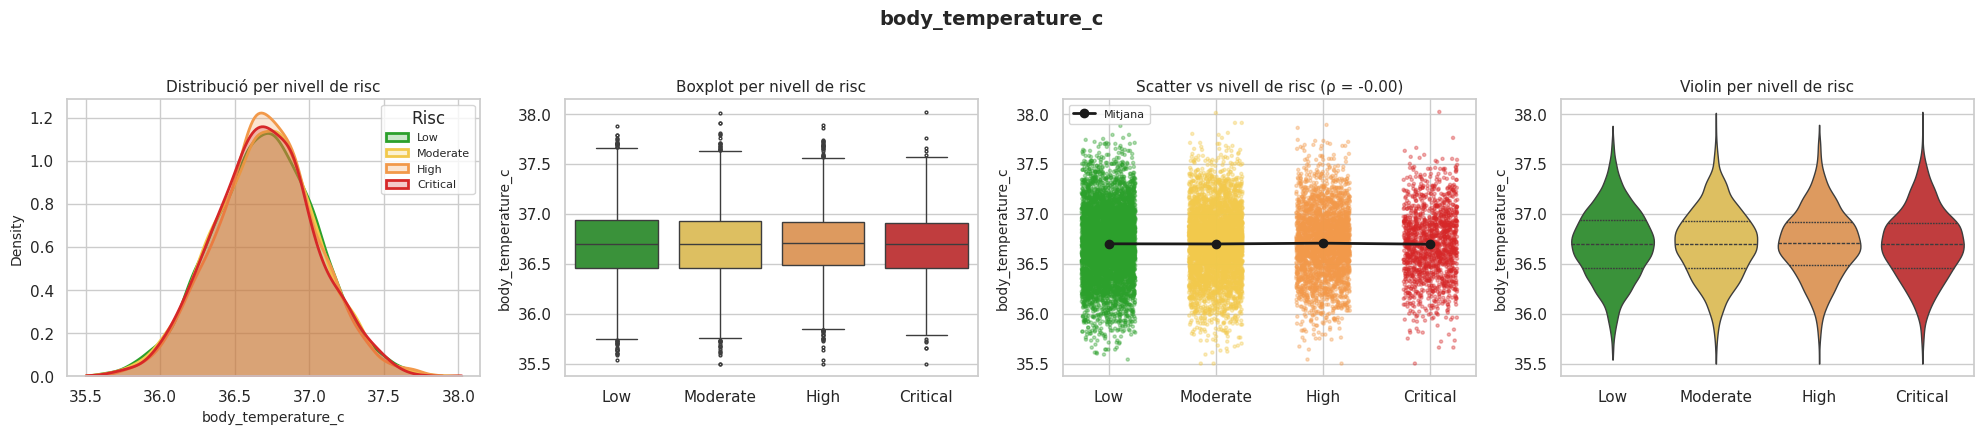

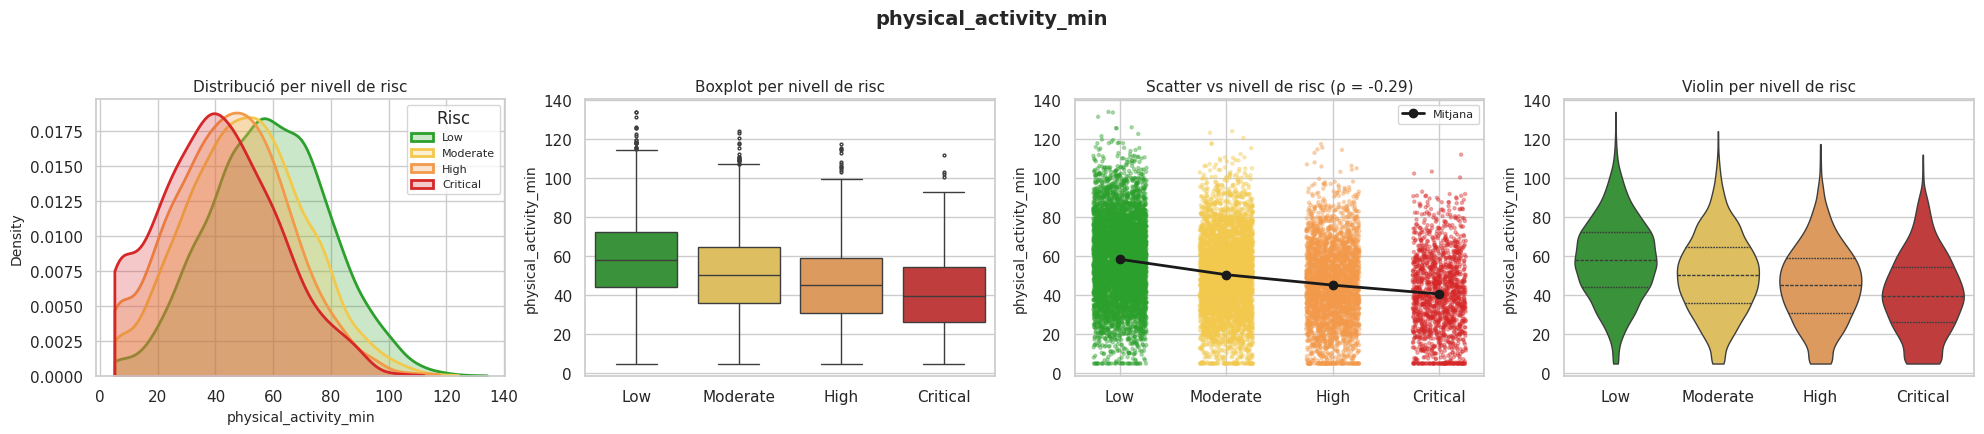

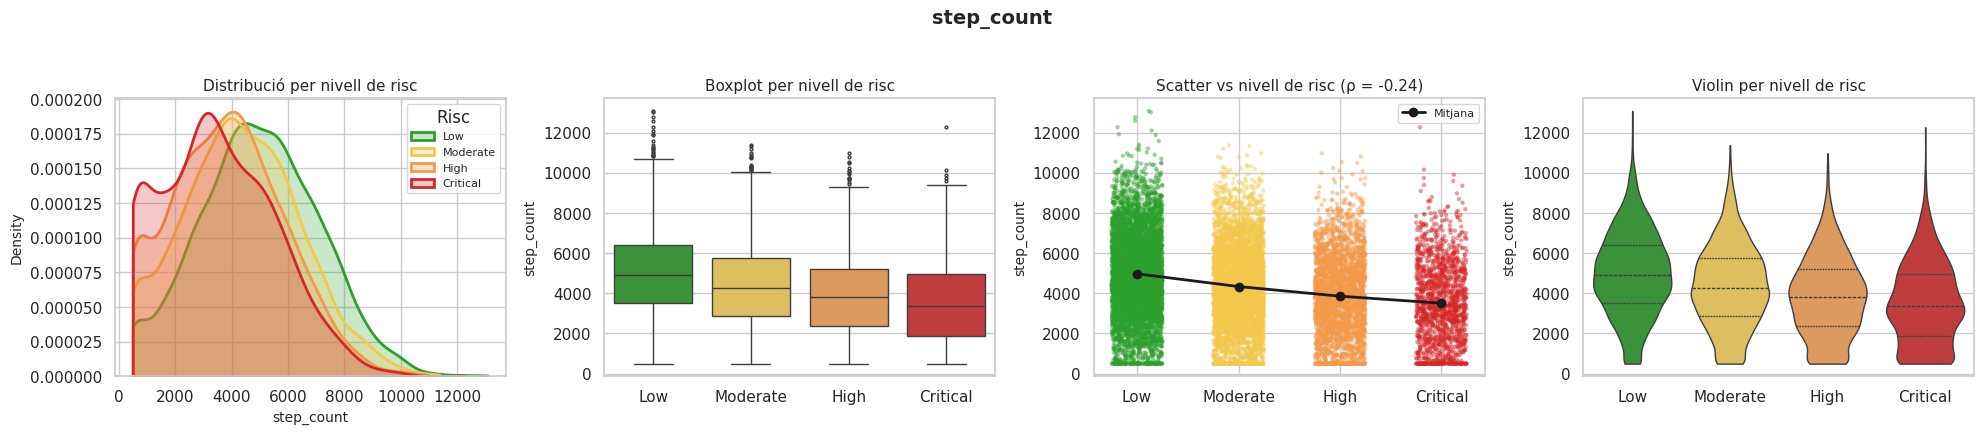

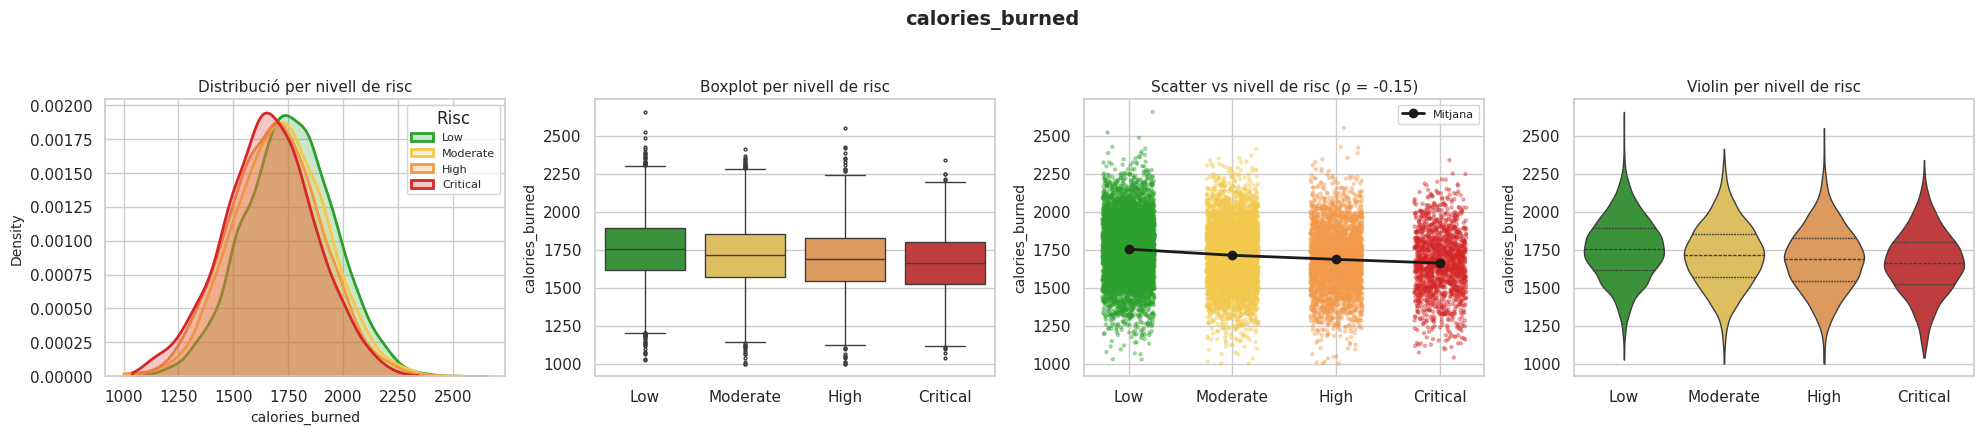

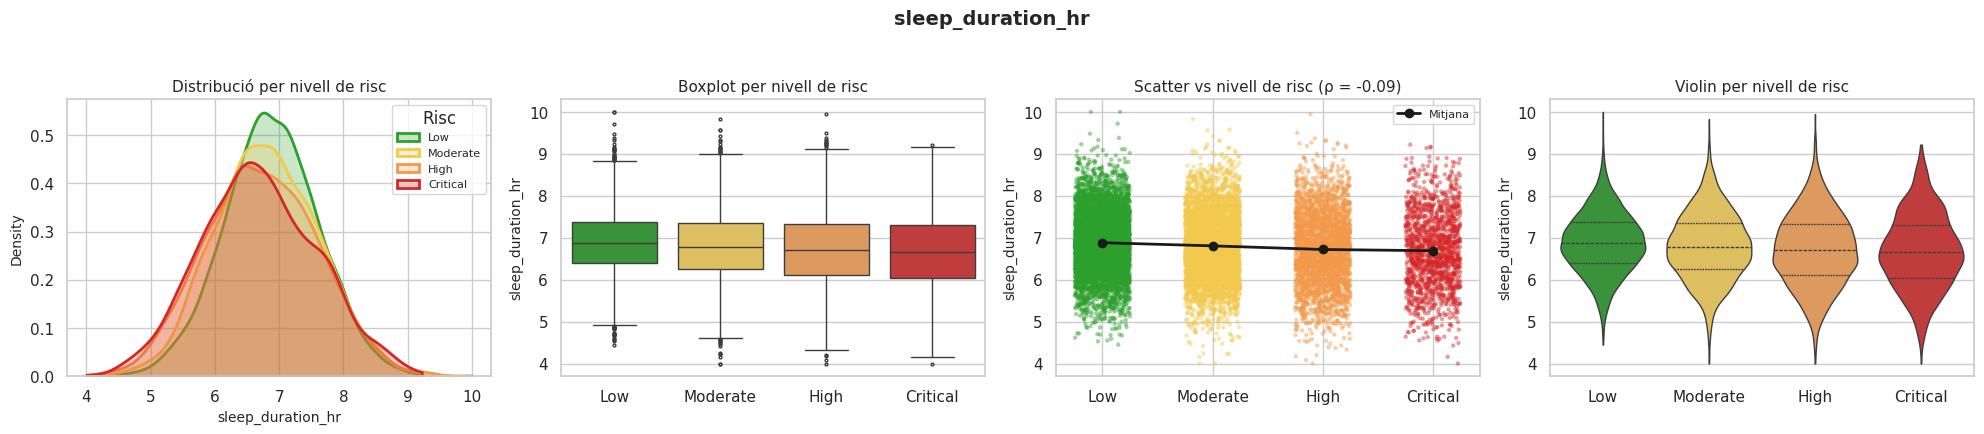

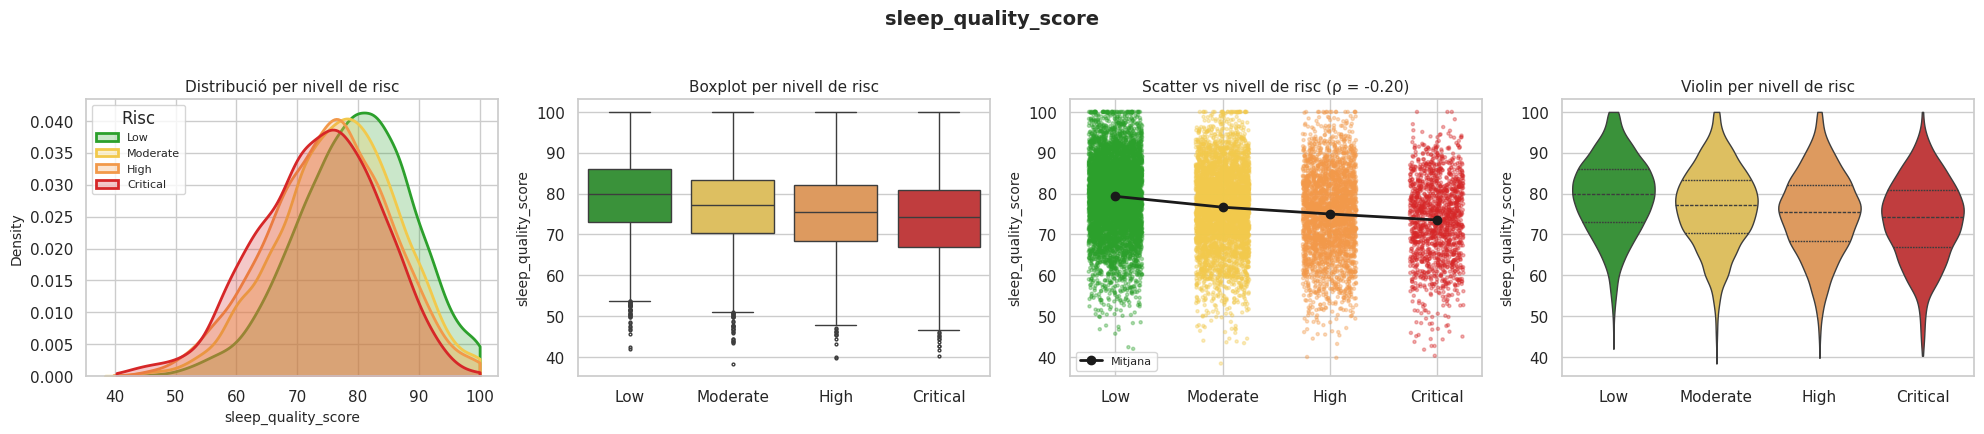

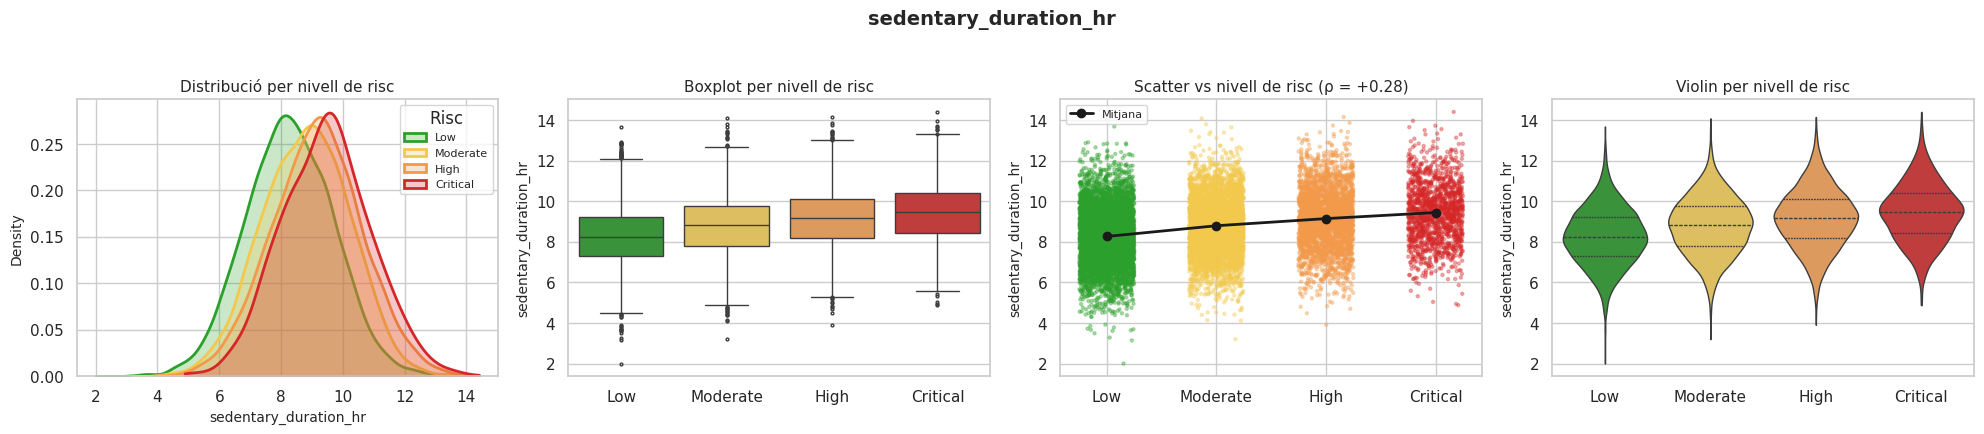

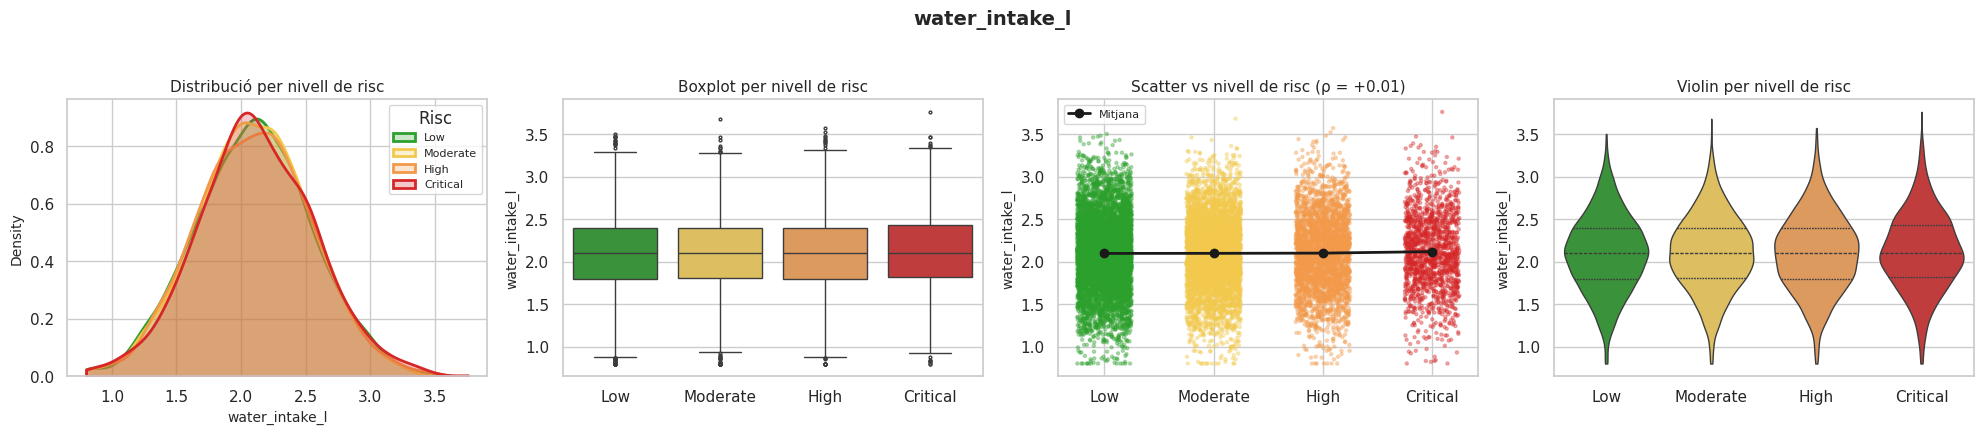

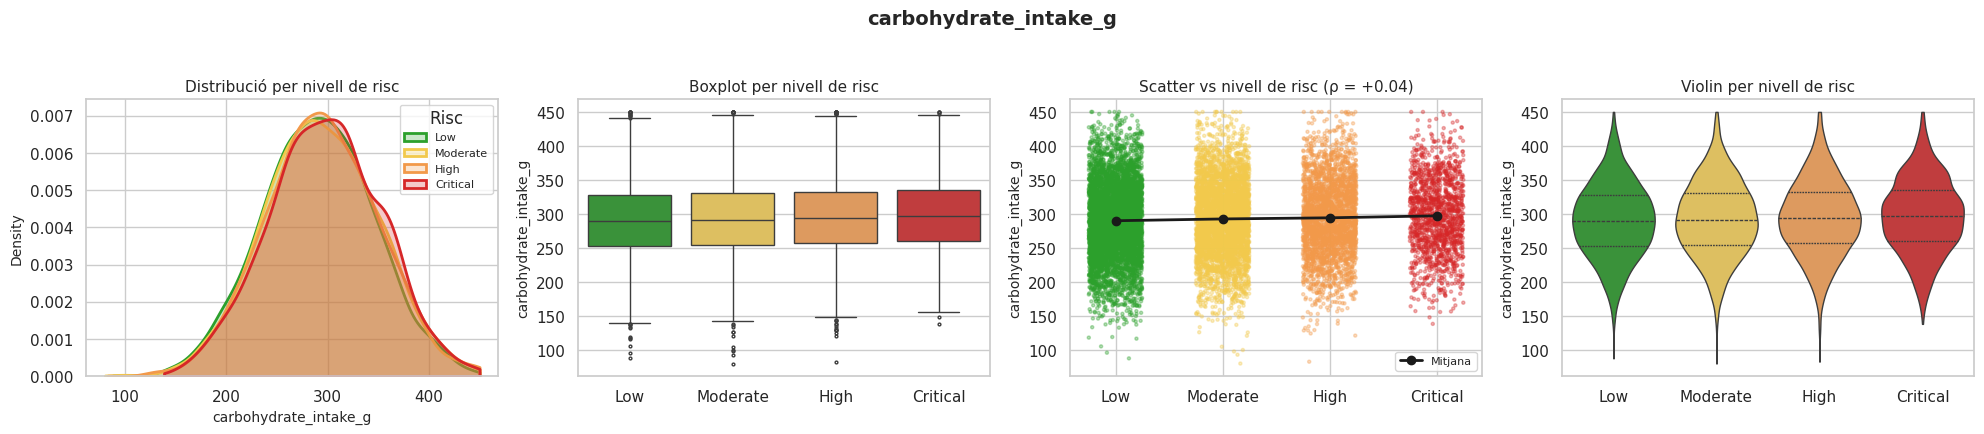

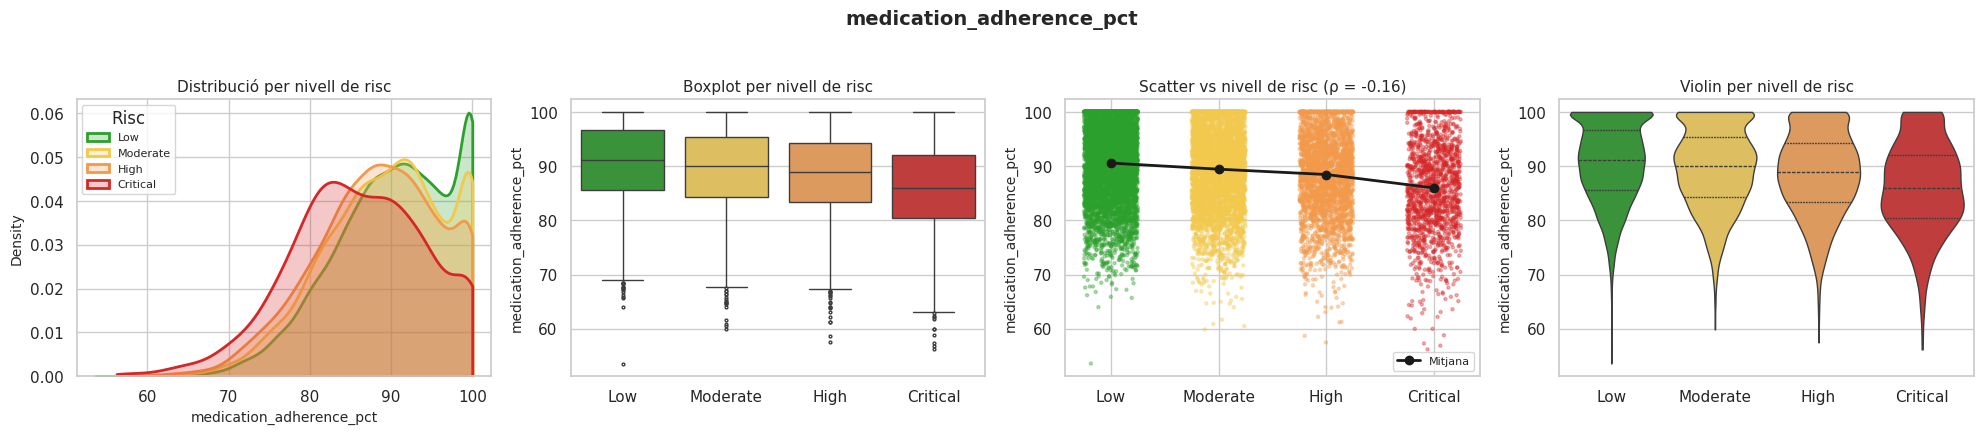

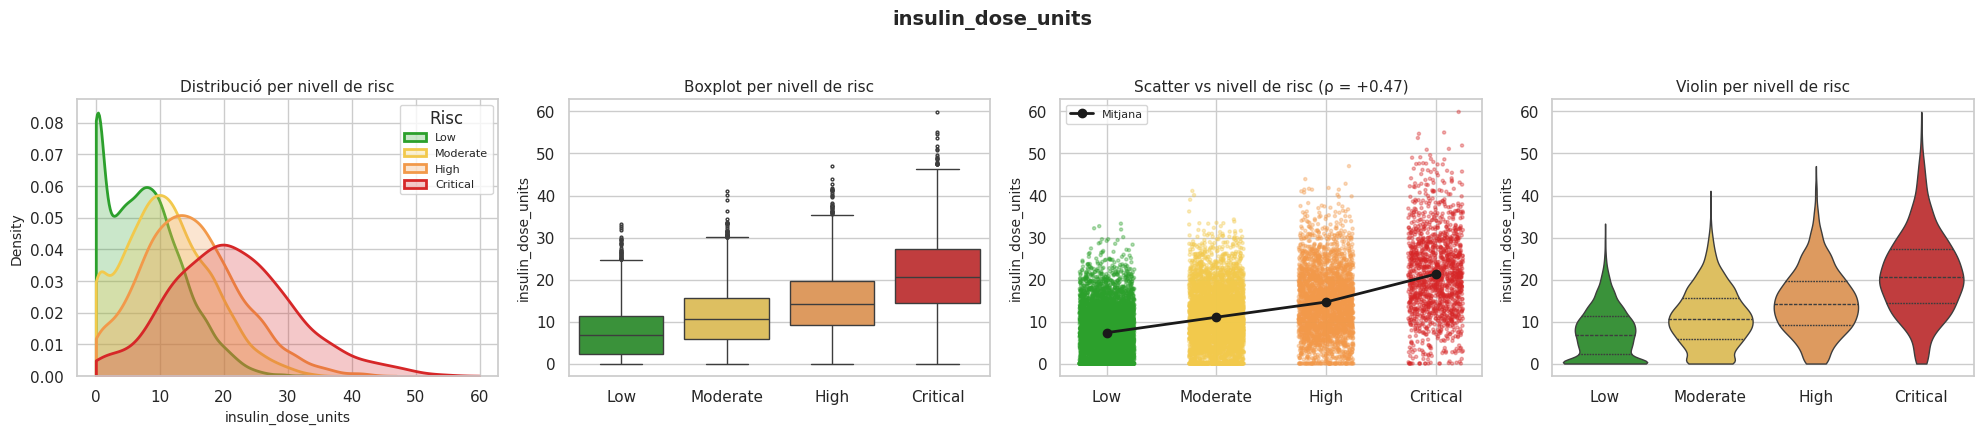

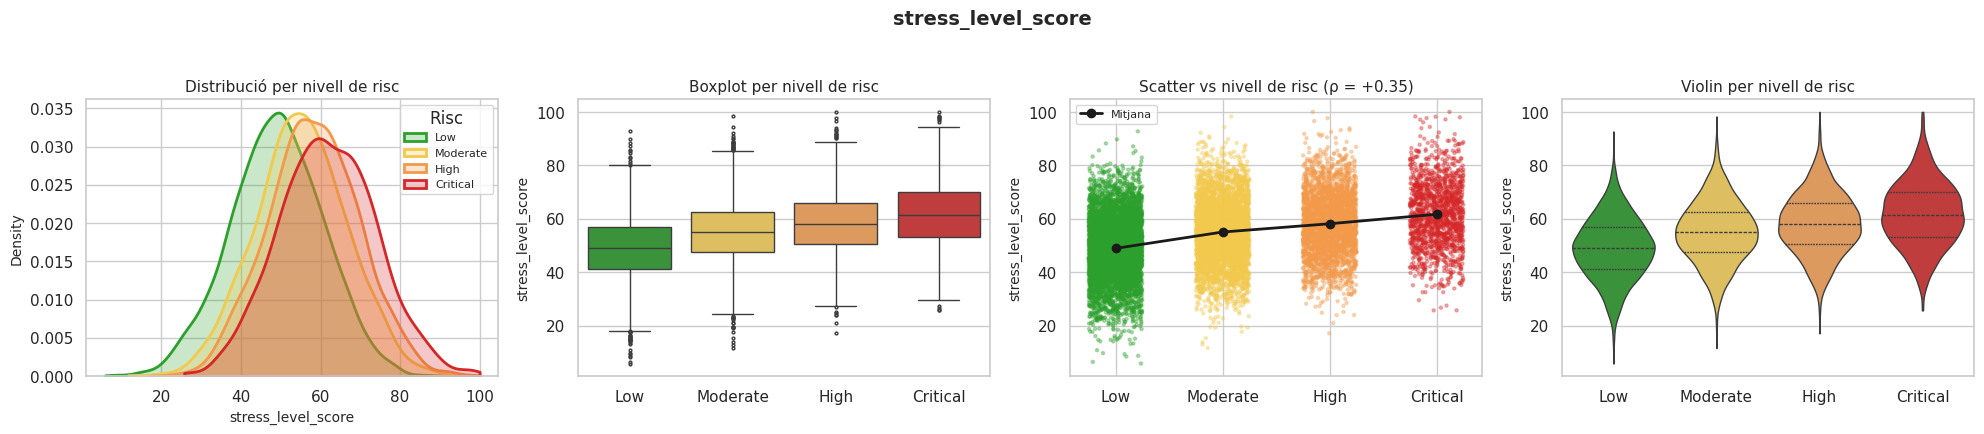

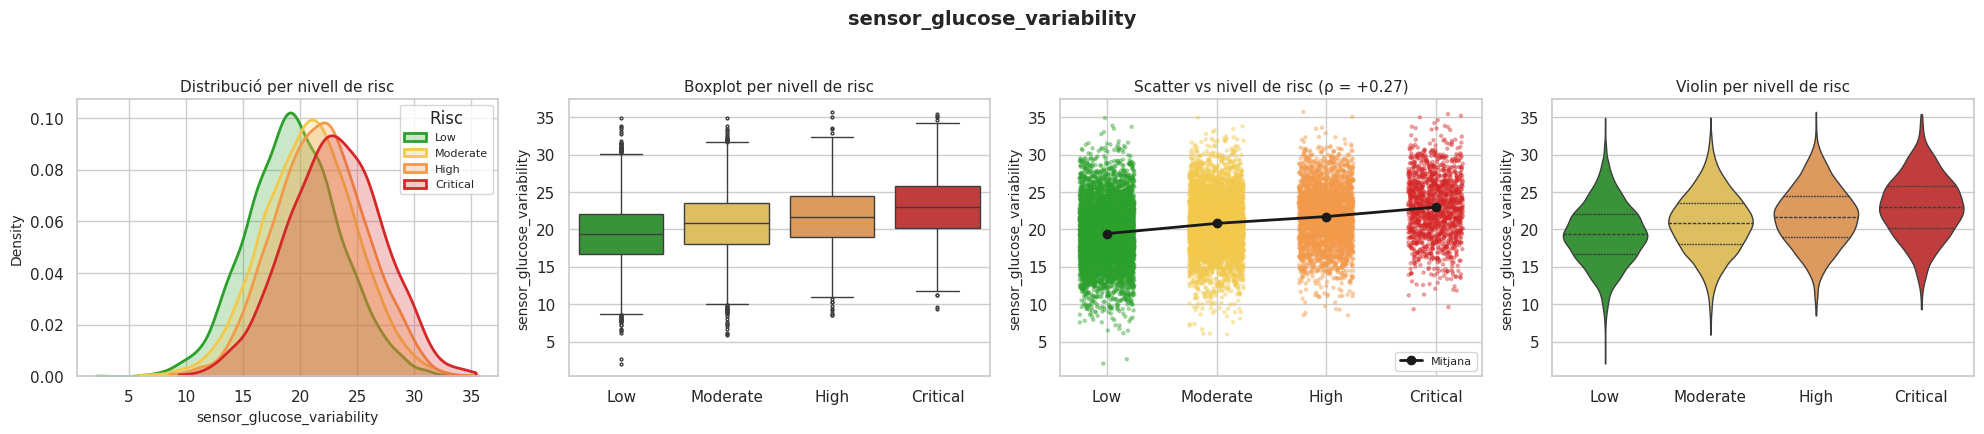

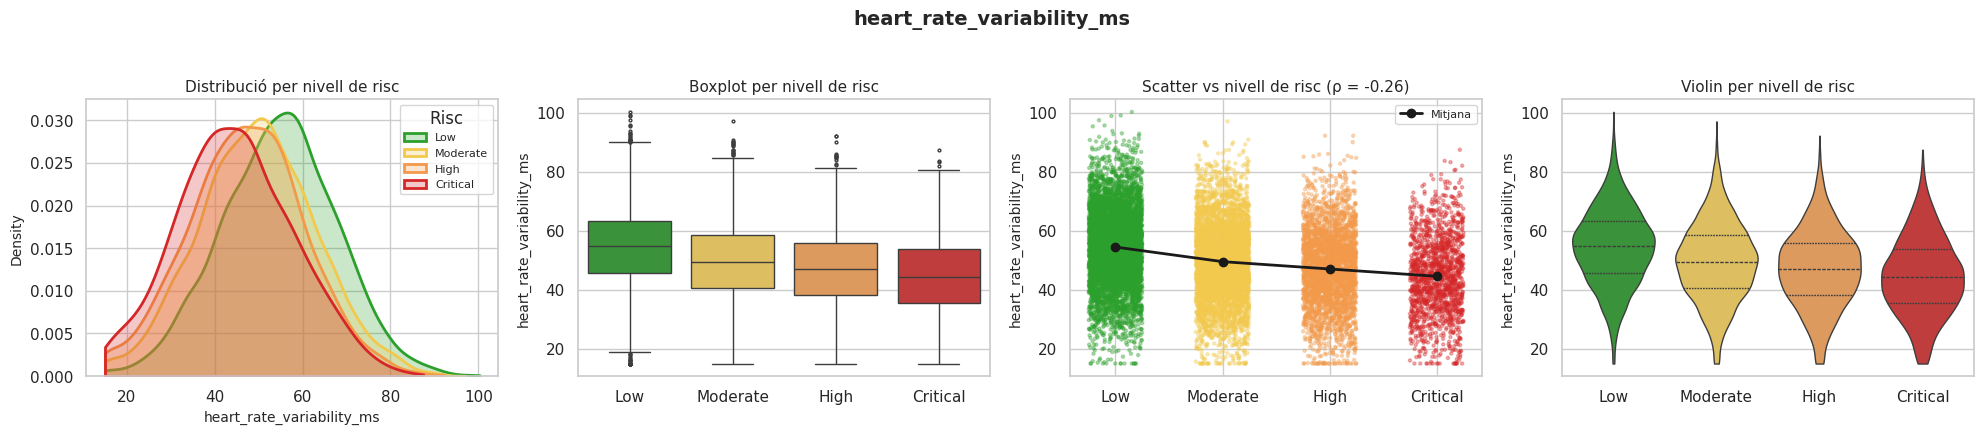

In [ ]:
rng = np.random.default_rng(SEED)

def plot_continua(col):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
    rho, _ = spearmanr(df[col], risk_num)

    for o in ORDER:                                   # 1) densitat (cut=0: no surt del rang real)
        sub = df.loc[df[TARGET] == o, col]
        sns.kdeplot(sub, ax=axes[0], color=COLORS[o], fill=True, alpha=0.25, linewidth=2,
                    label=LABELS[o], cut=0, warn_singular=False)
    axes[0].set_title("Distribució per nivell de risc"); axes[0].set_xlabel(col)
    axes[0].legend(title="Risc", fontsize=8)

    sns.boxplot(data=df, x=TARGET, y=col, order=ORDER, palette=PAL4, ax=axes[1], fliersize=2, linewidth=1)
    axes[1].set_xticks(range(4)); axes[1].set_xticklabels(ETIQ)
    axes[1].set_title("Boxplot per nivell de risc"); axes[1].set_xlabel("")

    x = risk_num + rng.uniform(-0.25, 0.25, len(df))  # 3) scatter amb jitter + mitjana
    axes[2].scatter(x, df[col], c=df[TARGET].map(COLORS), s=5, alpha=0.35)
    means = df.groupby(TARGET, observed=True)[col].mean().reindex(ORDER)
    axes[2].plot(range(4), means.values, "k-o", lw=2, ms=6, label="Mitjana")
    axes[2].set_xticks(range(4)); axes[2].set_xticklabels(ETIQ)
    axes[2].set_title(f"Scatter vs nivell de risc (ρ = {rho:+.2f})"); axes[2].set_ylabel(col)
    axes[2].legend(fontsize=8)

    sns.violinplot(data=df, x=TARGET, y=col, order=ORDER, palette=PAL4, ax=axes[3],
                   inner="quartile", cut=0, linewidth=1)
    axes[3].set_xticks(range(4)); axes[3].set_xticklabels(ETIQ)
    axes[3].set_title("Violin per nivell de risc"); axes[3].set_xlabel("")

    fig.suptitle(col, fontsize=14, fontweight="bold", y=1.03)
    plt.tight_layout(); plt.show()

for col in CONT_COLS:
    plot_continua(col)

Cel·la 12 · Gràfics de barres de TOTES les categòriques

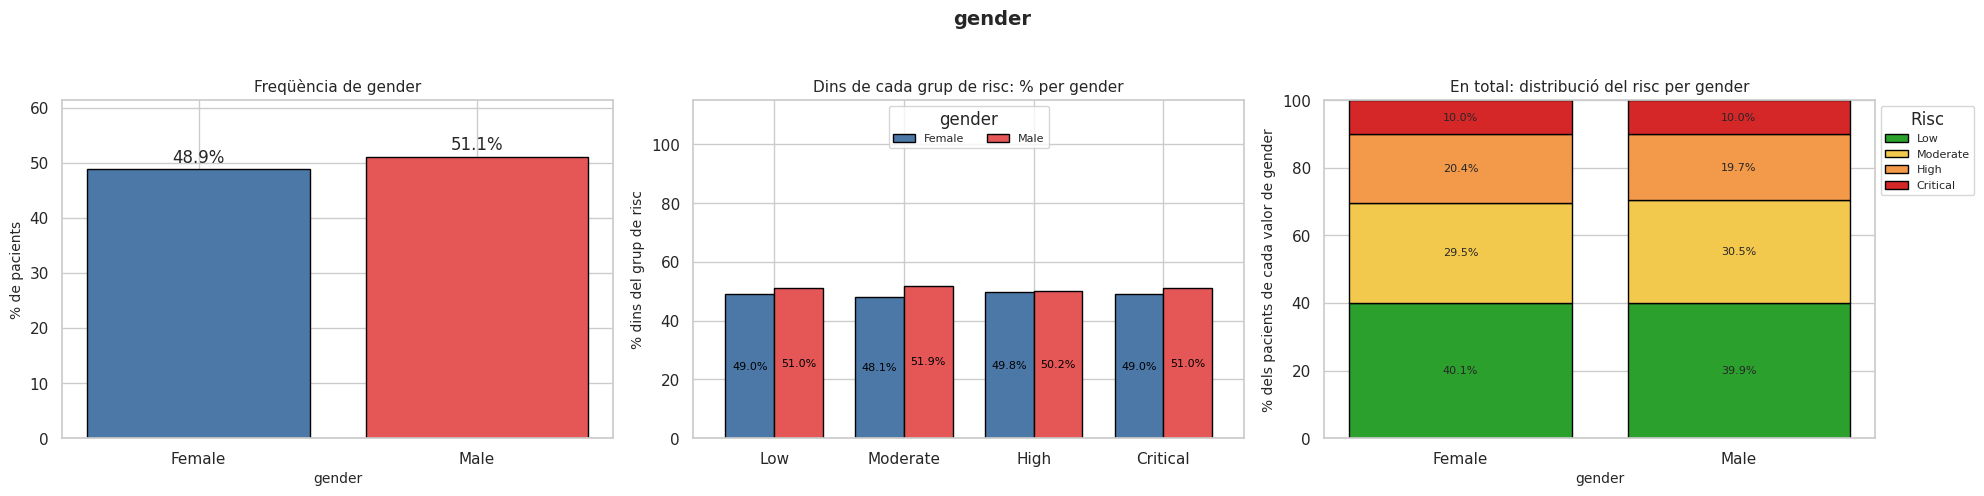

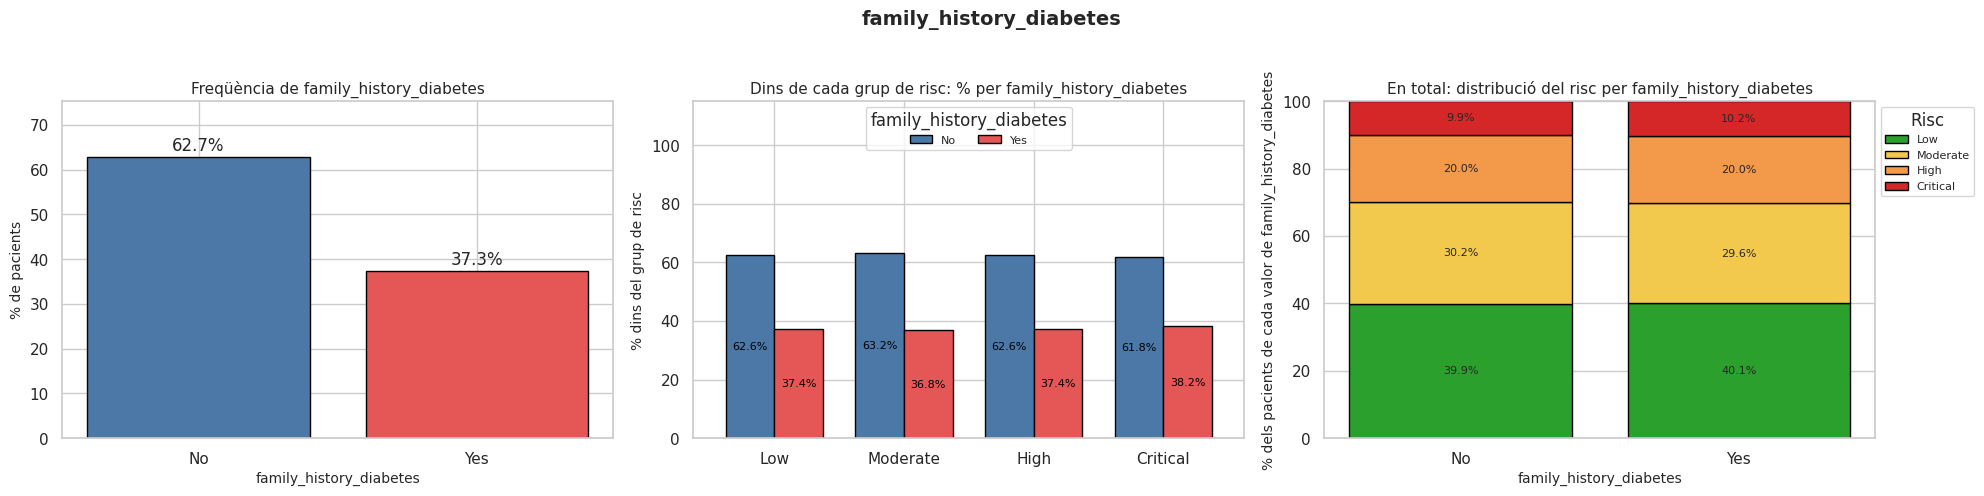

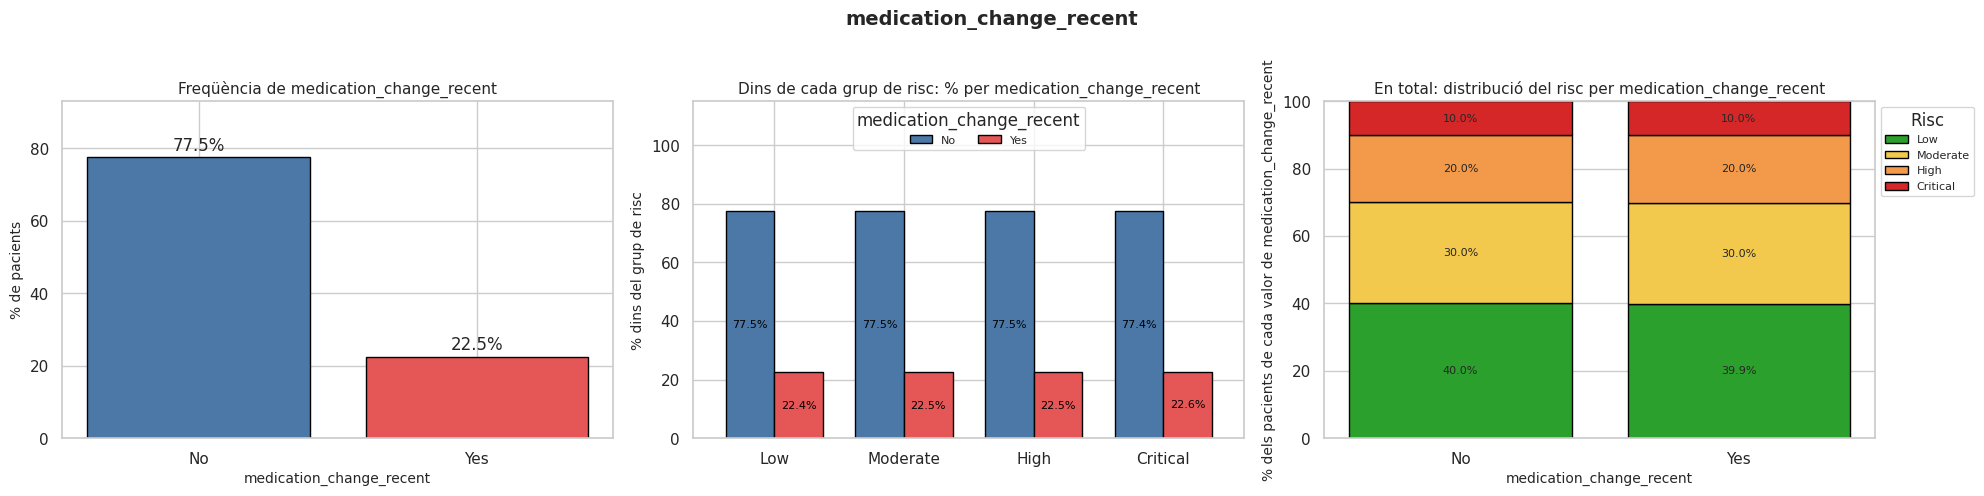

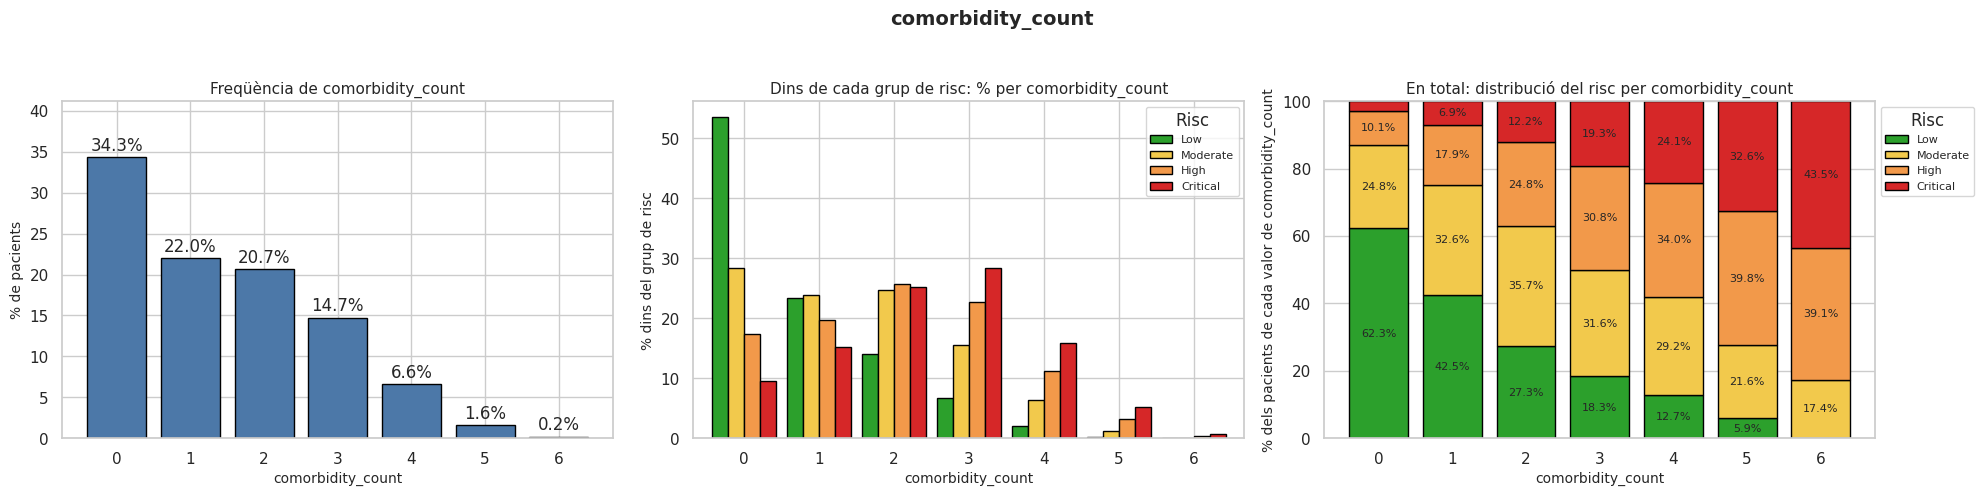

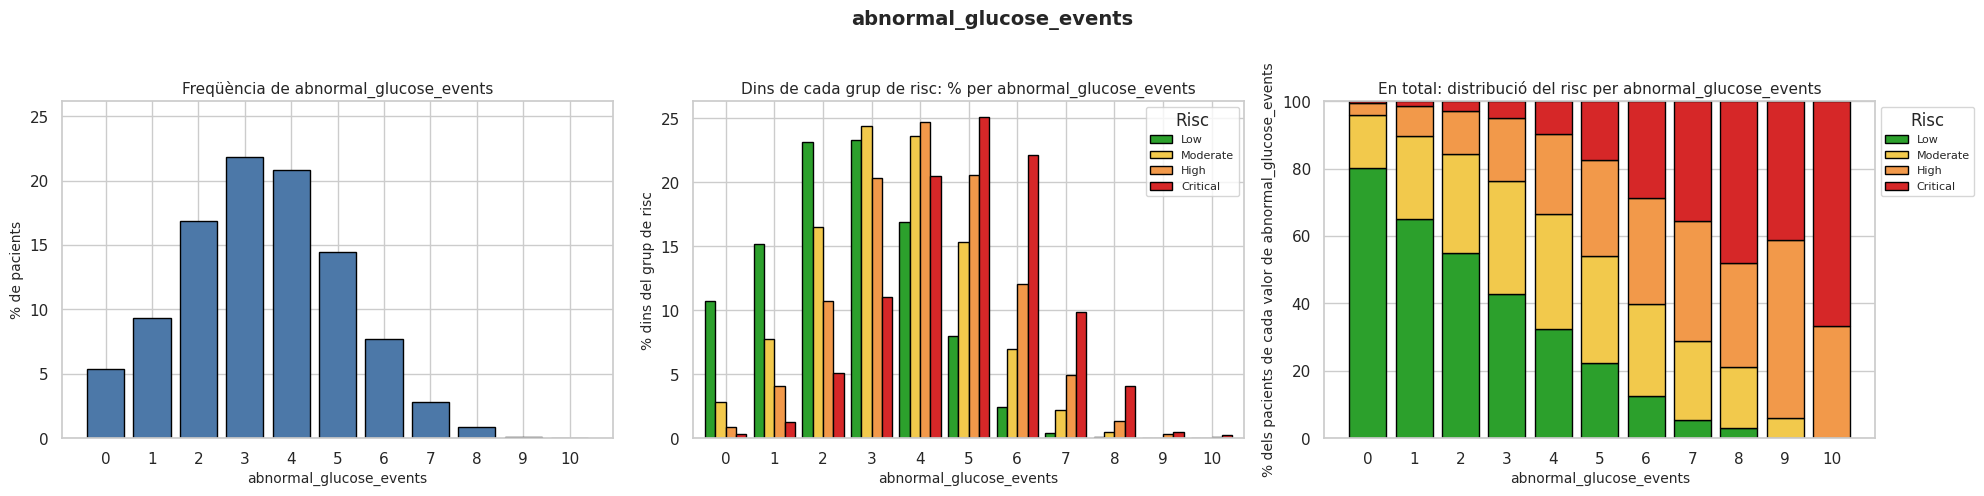

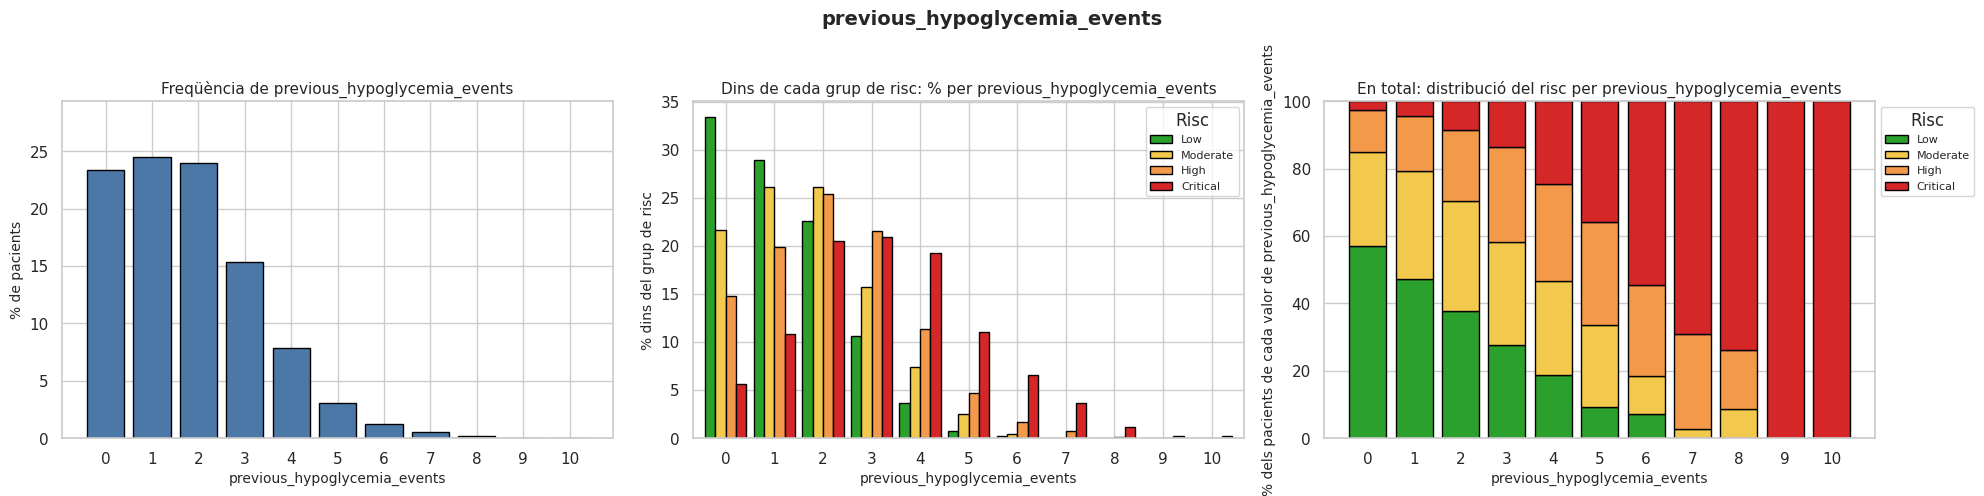

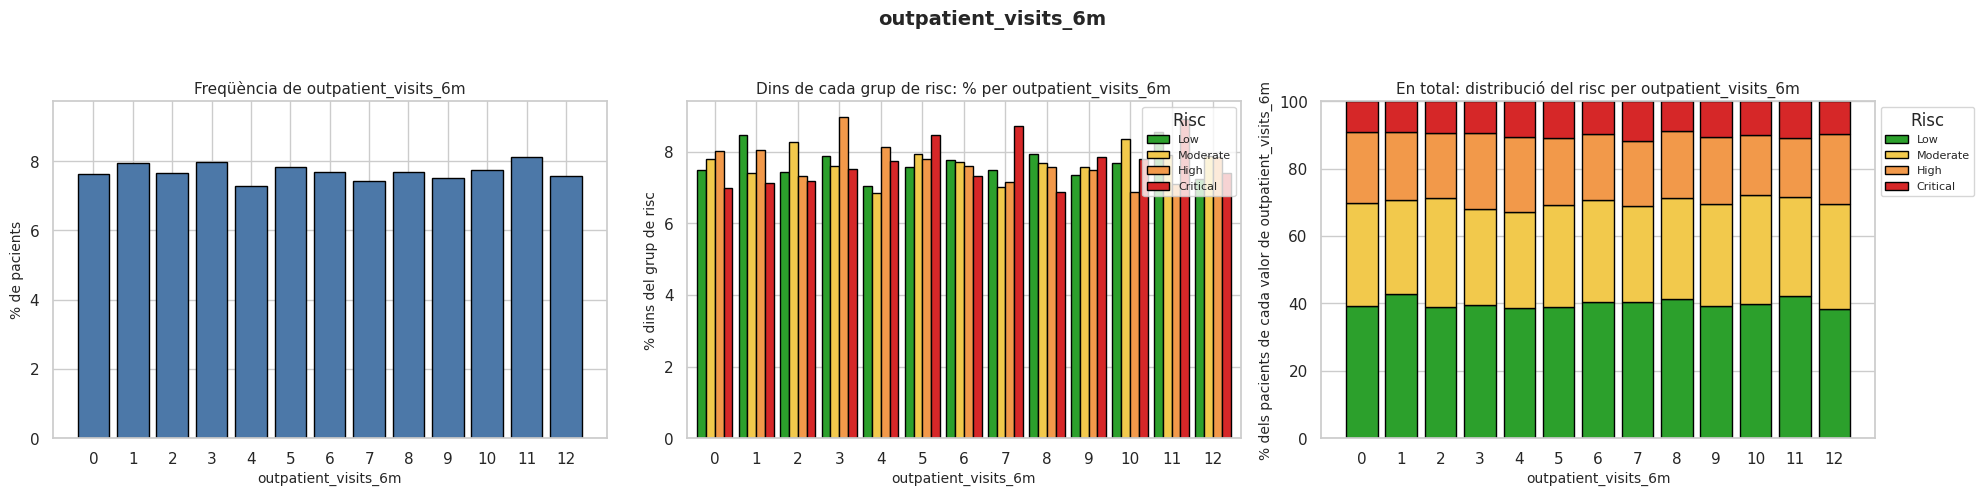

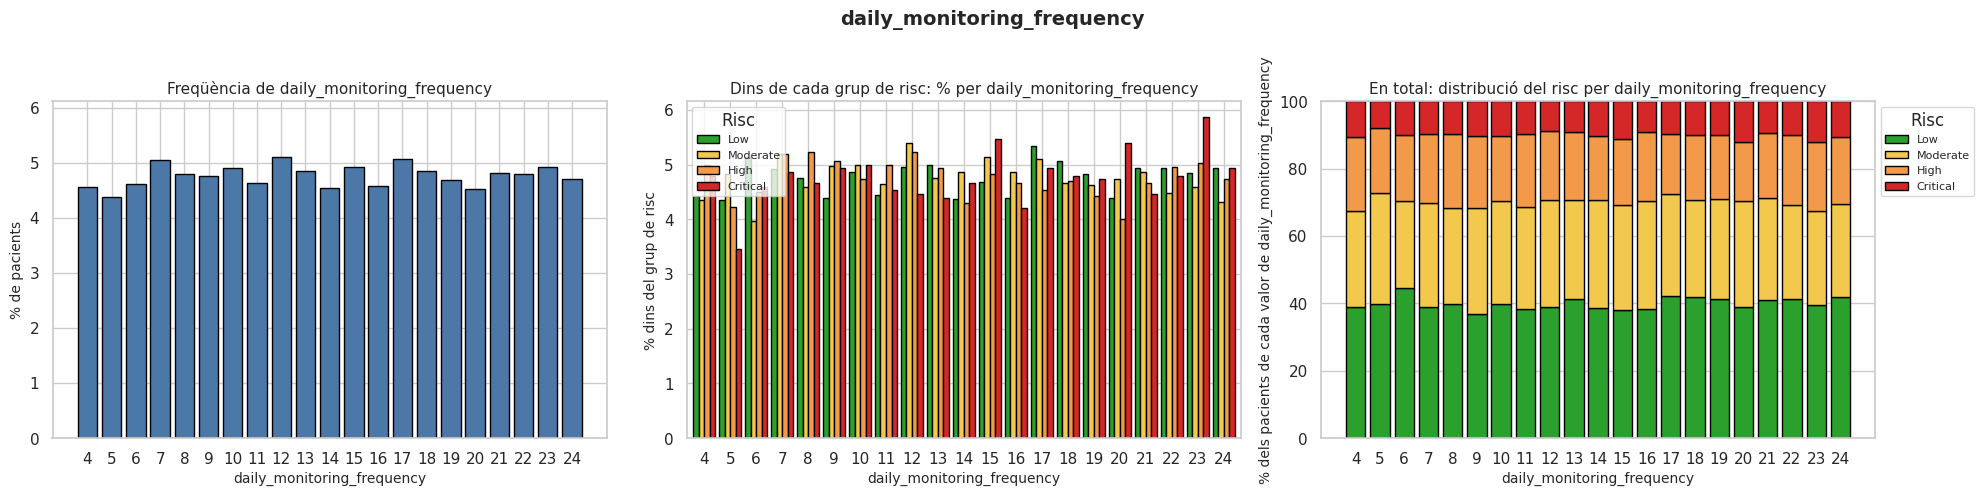

In [ ]:
def annotate(ax, fmt="{:.1f}%"):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(v) if v > 0 else "" for v in c.datavalues],
                     label_type="center", fontsize=8, color="black")

def plot_categorica(col):
    cats = sorted(df[col].unique()); k = len(cats); binaria = (k == 2)
    etiquetes = [str(c) for c in cats]
    fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))

    # 1) Freqüència total (% de pacients de cada categoria)
    freq = df[col].value_counts(normalize=True).reindex(cats) * 100
    b = axes[0].bar(etiquetes, freq.values, color=CAT_PALETTE[:k] if binaria else "#4C78A8", edgecolor="black")
    if k <= 7:
        axes[0].bar_label(b, labels=[f"{v:.1f}%" for v in freq.values], padding=2)
    axes[0].set_ylim(0, freq.max() * 1.2); axes[0].set_ylabel("% de pacients")
    axes[0].set_xlabel(col); axes[0].set_title(f"Freqüència de {col}")

    # 2) DINS de cada grup de risc: cada grup de risc suma 100%
    if binaria:
        within = pd.crosstab(df[TARGET], df[col], normalize="index").reindex(ORDER) * 100
        within.index = ETIQ
        within.plot(kind="bar", ax=axes[1], color=CAT_PALETTE[:k], edgecolor="black", width=0.75)
        annotate(axes[1]); axes[1].set_ylim(0, 115)
        axes[1].legend(title=col, ncol=2, loc="upper center", fontsize=8)
        axes[1].set_xlabel("")
    else:
        within = pd.crosstab(df[col], df[TARGET], normalize="columns")[ORDER] * 100
        within.columns = ETIQ
        within.plot(kind="bar", ax=axes[1], color=PAL4, edgecolor="black", width=0.85)
        axes[1].legend(title="Risc", fontsize=8); axes[1].set_xlabel(col)
    axes[1].set_ylabel("% dins del grup de risc")
    axes[1].set_title(f"Dins de cada grup de risc: % per {col}")
    axes[1].tick_params(axis="x", rotation=0)

    # 3) EN TOTAL: de tots els pacients d'una categoria, quin % és de cada grup de risc (cada barra suma 100%)
    total = pd.crosstab(df[col], df[TARGET], normalize="index")[ORDER] * 100
    bottom = np.zeros(len(total))
    for o in ORDER:
        bars = axes[2].bar(etiquetes, total[o].values, bottom=bottom, color=COLORS[o],
                           edgecolor="black", label=LABELS[o])
        if k <= 7:
            for rect, v, btm in zip(bars, total[o].values, bottom):
                if v >= 3:
                    axes[2].text(rect.get_x() + rect.get_width() / 2, btm + v / 2, f"{v:.1f}%",
                                 ha="center", va="center", fontsize=8)
        bottom += total[o].values
    axes[2].set_ylim(0, 100); axes[2].set_ylabel(f"% dels pacients de cada valor de {col}")
    axes[2].set_xlabel(col); axes[2].set_title(f"En total: distribució del risc per {col}")
    axes[2].legend(title="Risc", bbox_to_anchor=(1, 1), fontsize=8)

    fig.suptitle(col, fontsize=14, fontweight="bold", y=1.03)
    plt.tight_layout(); plt.show()

for col in CATEG_COLS:
    plot_categorica(col)

Cel·la 13 · Correlació amb el risc

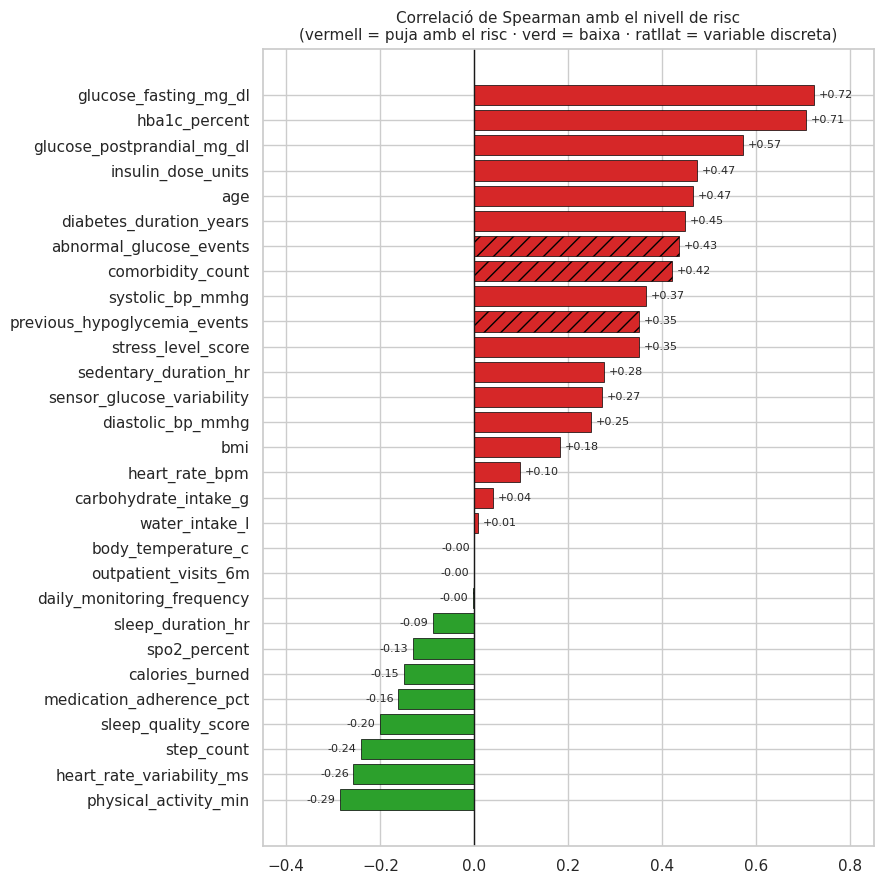

,rho,p,tipus,p_holm
variable,,,,
physical_activity_min,-0.2864,<0.001,contínua,<0.001
heart_rate_variability_ms,-0.2573,<0.001,contínua,<0.001
step_count,-0.2411,<0.001,contínua,<0.001
sleep_quality_score,-0.2014,<0.001,contínua,<0.001
medication_adherence_pct,-0.1614,<0.001,contínua,<0.001
calories_burned,-0.1501,<0.001,contínua,<0.001
spo2_percent,-0.1311,<0.001,contínua,<0.001
sleep_duration_hr,-0.0887,<0.001,contínua,<0.001
daily_monitoring_frequency,-0.0035,0.665,discreta,1.000


In [ ]:
rows = []
for c in NUM_COLS:
    r, p = spearmanr(df[c], risk_num)
    rows.append({"variable": c, "rho": r, "p": p, "tipus": "discreta" if c in DISC_COLS else "contínua"})
corr = pd.DataFrame(rows).set_index("variable")
corr["p_holm"] = holm(corr["p"])
corr = corr.sort_values("rho")

fig, ax = plt.subplots(figsize=(9, 9))
for i, (c, fila) in enumerate(corr.iterrows()):
    ax.barh(i, fila["rho"], color="#d62728" if fila["rho"] >= 0 else "#2ca02c", edgecolor="black",
            linewidth=0.5, hatch="//" if fila["tipus"] == "discreta" else None)
    ax.text(fila["rho"] + (0.01 if fila["rho"] >= 0 else -0.01), i, f"{fila['rho']:+.2f}",
            va="center", ha="left" if fila["rho"] >= 0 else "right", fontsize=8)
ax.set_xlim(-0.45, 0.85)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
ax.axvline(0, color="k", lw=1)
ax.set_title("Correlació de Spearman amb el nivell de risc\n"
             "(vermell = puja amb el risc · verd = baixa · ratllat = variable discreta)")
plt.tight_layout(); plt.show()
display(amb_p(corr, ["p", "p_holm"]).round(4))

Cel·la 14 · Robustesa del criteri de normalitat

Variables on el criteri de normalitat és fràgil: ['glucose_fasting_mg_dl', 'glucose_postprandial_mg_dl', 'sleep_duration_hr', 'carbohydrate_intake_g', 'sensor_glucose_variability', 'heart_rate_variability_ms']


,p_ANOVA,p_Kruskal,mateixa_decisió
variable,,,
glucose_fasting_mg_dl,<0.001,<0.001,True
glucose_postprandial_mg_dl,<0.001,<0.001,True
sleep_duration_hr,<0.001,<0.001,True
carbohydrate_intake_g,<0.001,<0.001,True
sensor_glucose_variability,<0.001,<0.001,True
heart_rate_variability_ms,<0.001,<0.001,True


En totes dues opcions la conclusió és la mateixa: True


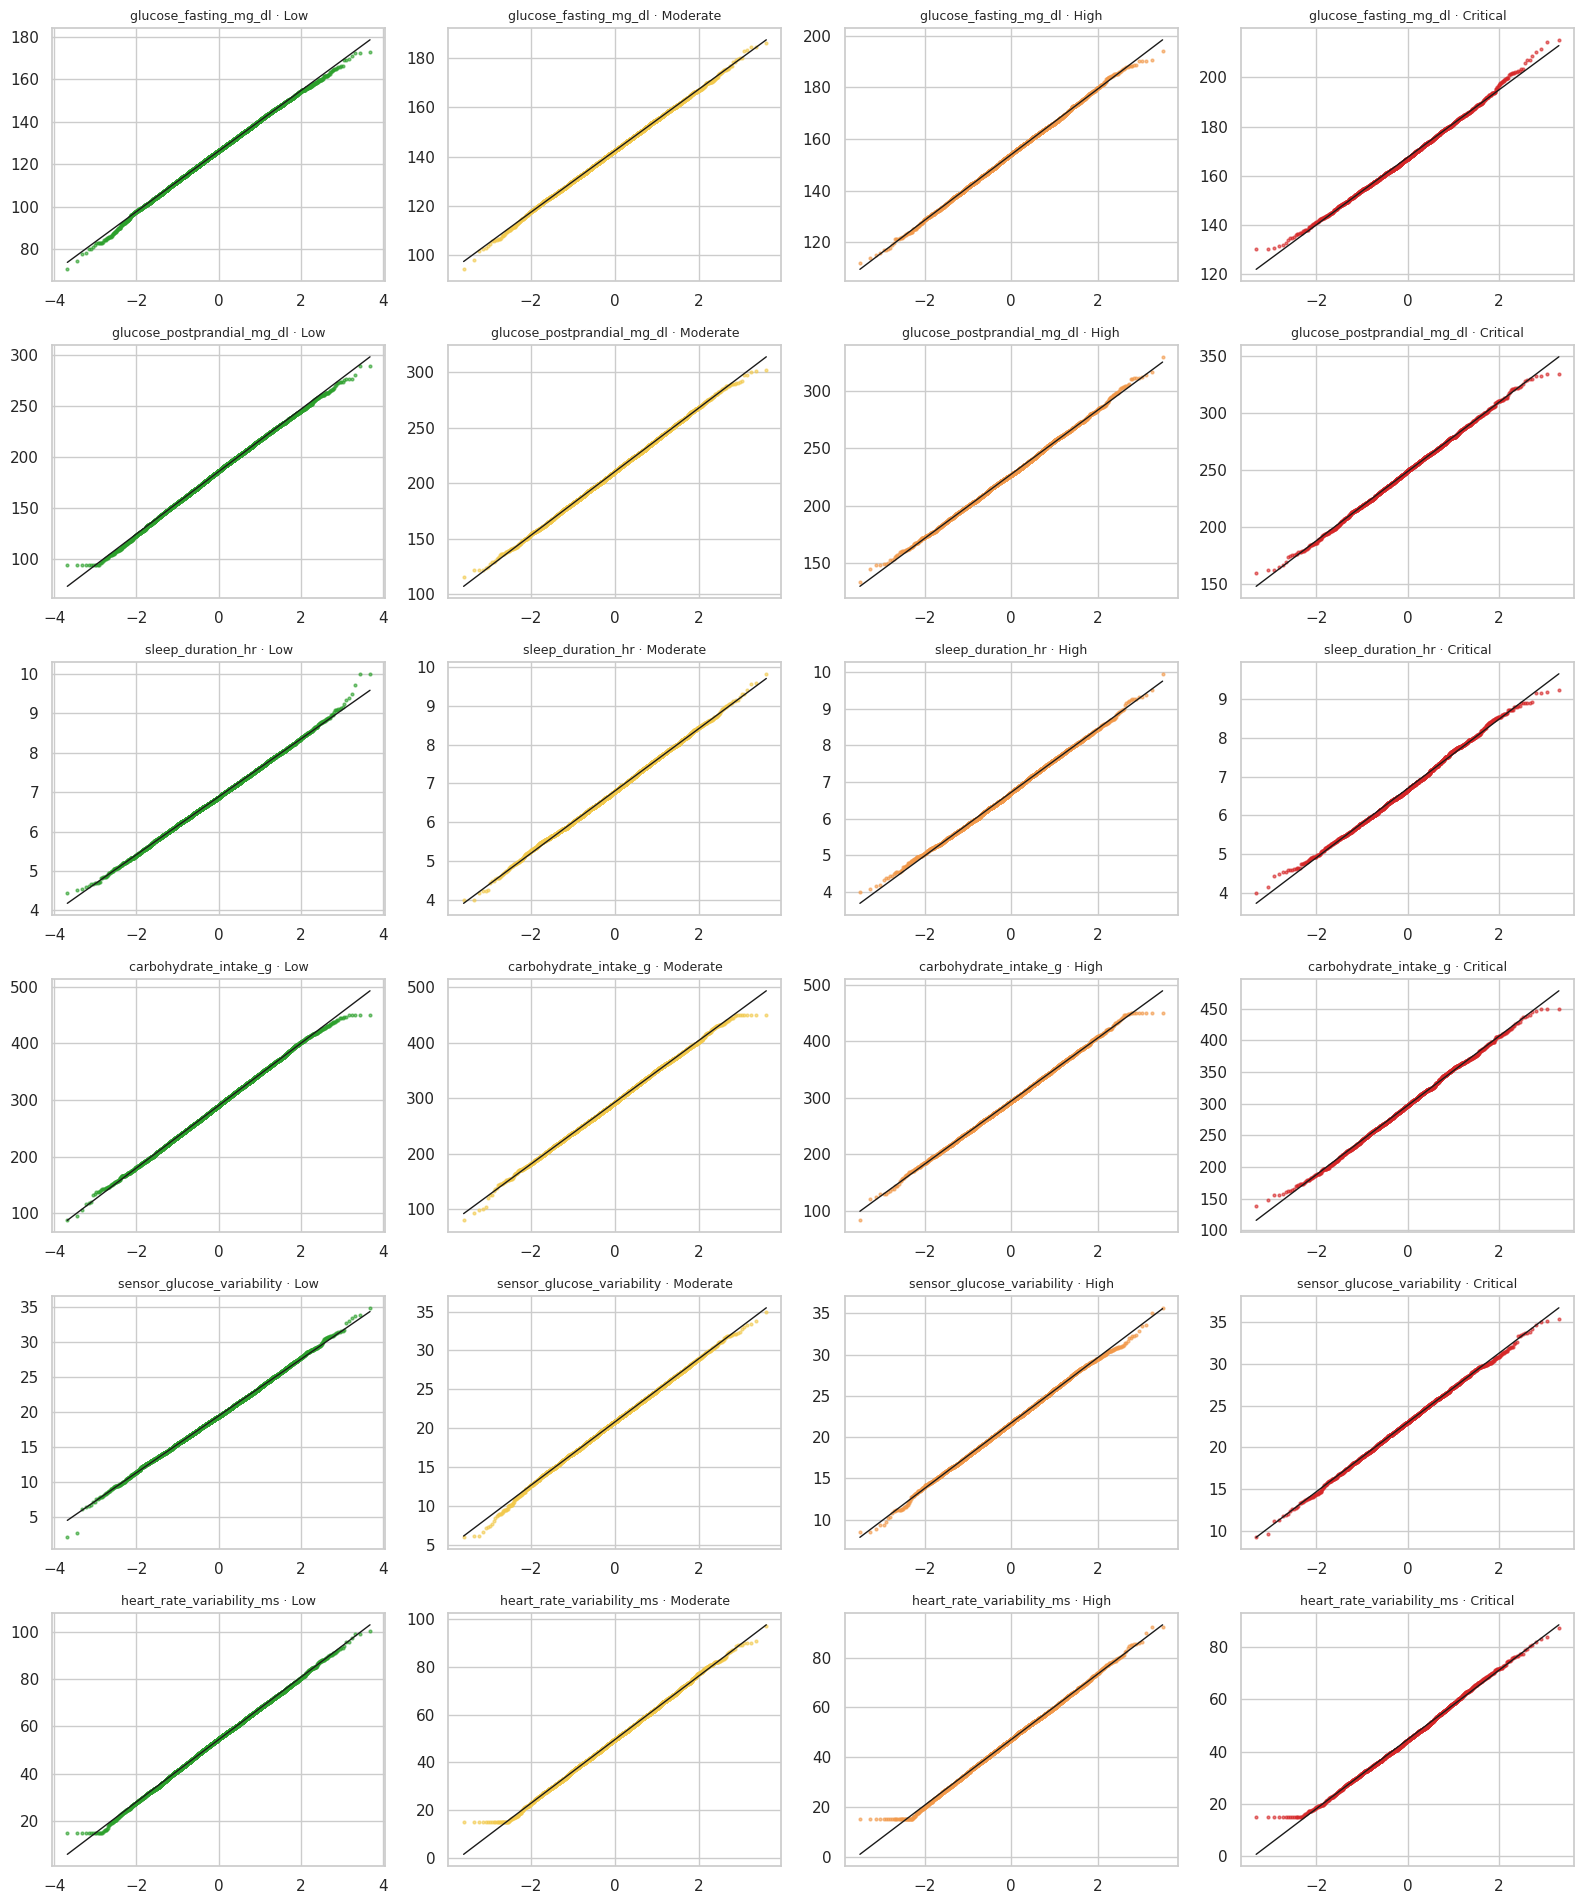

In [ ]:
# Variables on triar "amb" o "sense" correcció de Holm canvia el test (ANOVA <-> Kruskal-Wallis)
fragils = list(norm.index[norm["normal_sense_correccio"] != norm["normal_amb_Holm"]])
print("Variables on el criteri de normalitat és fràgil:", fragils)

rows = []
for col in fragils:
    g = [df.loc[df[TARGET] == o, col].values for o in ORDER]
    pa, pk = stats.f_oneway(*g)[1], stats.kruskal(*g)[1]
    rows.append({"variable": col, "p_ANOVA": pa, "p_Kruskal": pk,
                 "mateixa_decisió": (pa < ALPHA) == (pk < ALPHA)})
rob = pd.DataFrame(rows).set_index("variable")
if len(rob):
    display(amb_p(rob, ["p_ANOVA", "p_Kruskal"]))
    print("En totes dues opcions la conclusió és la mateixa:", bool(rob["mateixa_decisió"].all()))

    fig, axes = plt.subplots(len(fragils), 4, figsize=(16, 3.2 * len(fragils)), squeeze=False)
    for i, col in enumerate(fragils):
        for j, o in enumerate(ORDER):
            (osm, osr), (sl, ic, _) = stats.probplot(df.loc[df[TARGET] == o, col], dist="norm")
            axes[i, j].scatter(osm, osr, s=4, color=COLORS[o], alpha=0.6)
            axes[i, j].plot(osm, sl * osm + ic, "k-", lw=1)
            axes[i, j].set_title(f"{col} · {LABELS[o]}", fontsize=9)
    plt.tight_layout(); plt.show()

Cel·la 15 · IC bootstrap de ε²

,eps2,IC95_inferior,IC95_superior
variable,,,
glucose_fasting_mg_dl,0.5239,0.5132,0.5344
hba1c_percent,0.5022,0.4915,0.5125
glucose_postprandial_mg_dl,0.3282,0.3168,0.3398
insulin_dose_units,0.2329,0.2216,0.2442
age,0.2173,0.2062,0.2293
diabetes_duration_years,0.2097,0.1984,0.2212
abnormal_glucose_events,0.1916,0.1806,0.2028
comorbidity_count,0.1774,0.1669,0.1890
systolic_bp_mmhg,0.1339,0.1239,0.1445


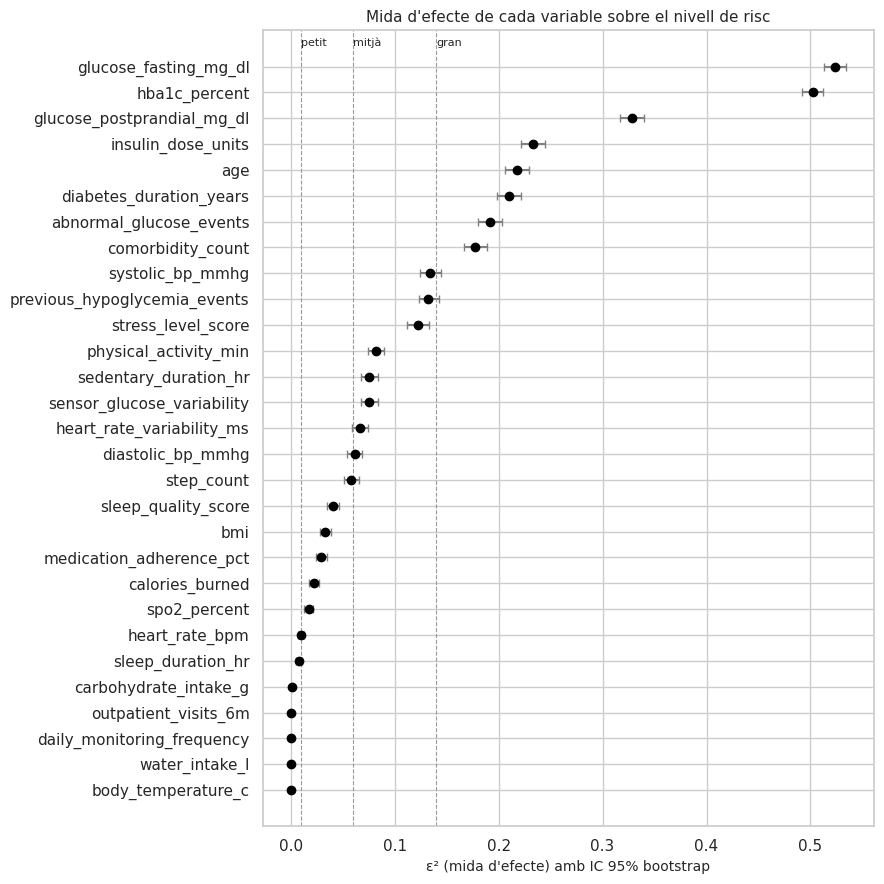

In [ ]:
rng_b = np.random.default_rng(SEED)
rows = []
for col in NUM_COLS:
    g = [df.loc[df[TARGET] == o, col].values for o in ORDER]
    N, k = sum(len(x) for x in g), len(g)
    boot = []
    for _ in range(N_BOOT):                                      # remostreig dins de cada grup
        gb = [x[rng_b.integers(0, len(x), len(x))] for x in g]
        boot.append((stats.kruskal(*gb)[0] - k + 1) / (N - k))
    lo, hi = np.percentile(boot, [2.5, 97.5])
    rows.append({"variable": col, "eps2": res.loc[col, "eps2_rangs"], "IC95_inferior": lo, "IC95_superior": hi})
ic = pd.DataFrame(rows).set_index("variable").sort_values("eps2", ascending=False)
display(ic.round(4))

fig, ax = plt.subplots(figsize=(9, 9))
y = np.arange(len(ic))[::-1]
ax.errorbar(ic["eps2"], y, xerr=[ic["eps2"] - ic["IC95_inferior"], ic["IC95_superior"] - ic["eps2"]],
            fmt="o", color="black", ecolor="gray", capsize=3)
for x0, lab in [(0.01, "petit"), (0.06, "mitjà"), (0.14, "gran")]:
    ax.axvline(x0, color="#999999", ls="--", lw=0.8); ax.text(x0, len(ic) - 0.2, lab, fontsize=8, ha="left")
ax.set_yticks(y); ax.set_yticklabels(ic.index); ax.set_xlabel("ε² (mida d'efecte) amb IC 95% bootstrap")
ax.set_title("Mida d'efecte de cada variable sobre el nivell de risc")
plt.tight_layout(); plt.show()

Cel·la 16 · Correlació parcial controlant l’edat

,rho_brut,rho_controlant_edat,p,p_holm,canvi
variable,,,,,
hba1c_percent,0.706,0.702,<0.001,<0.001,-0.005
glucose_fasting_mg_dl,0.723,0.659,<0.001,<0.001,-0.064
insulin_dose_units,0.475,0.515,<0.001,<0.001,0.040
glucose_postprandial_mg_dl,0.571,0.514,<0.001,<0.001,-0.057
diabetes_duration_years,0.447,0.512,<0.001,<0.001,0.065
previous_hypoglycemia_events,0.350,0.395,<0.001,<0.001,0.045
abnormal_glucose_events,0.434,0.393,<0.001,<0.001,-0.042
stress_level_score,0.349,0.285,<0.001,<0.001,-0.064
sensor_glucose_variability,0.272,0.262,<0.001,<0.001,-0.011


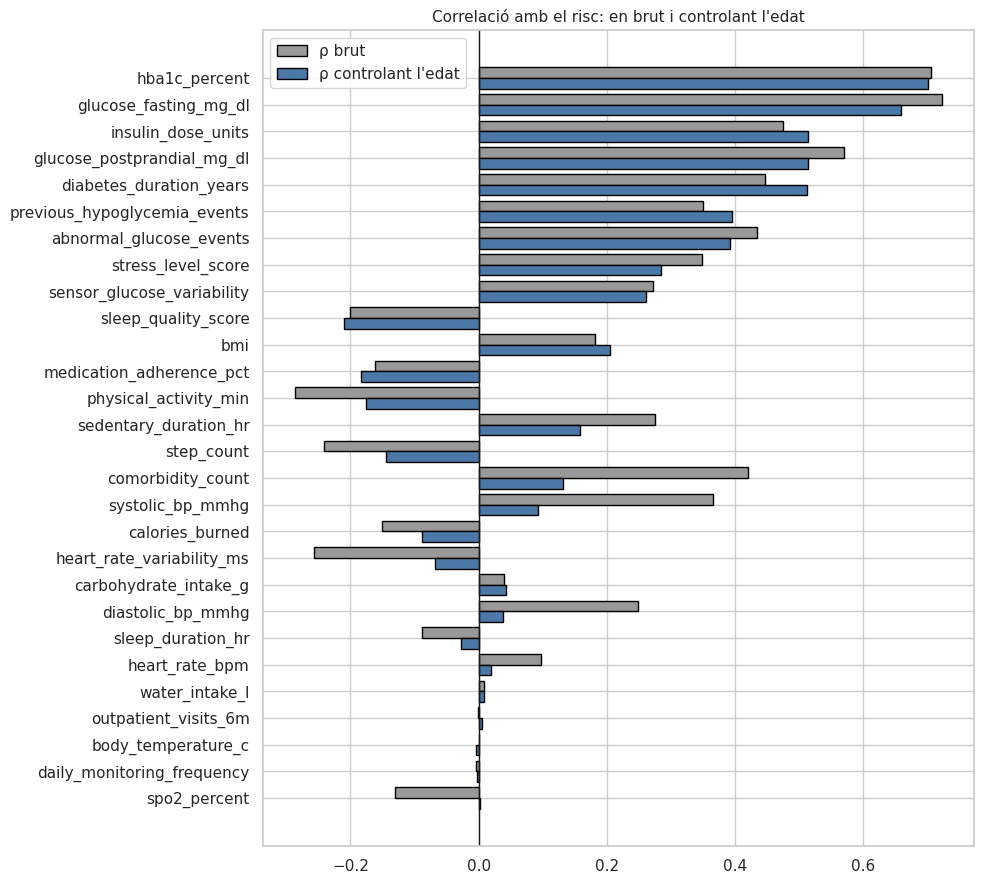

In [ ]:
def parcial_edat(v):
    """Spearman parcial entre v i el risc, eliminant l'efecte de l'edat (regressió sobre rangs)."""
    a, b, z = stats.rankdata(df[v]), stats.rankdata(risk_num), stats.rankdata(df["age"])
    Z = np.c_[np.ones(len(z)), z]
    ra = a - Z @ np.linalg.lstsq(Z, a, rcond=None)[0]
    rb = b - Z @ np.linalg.lstsq(Z, b, rcond=None)[0]
    r = np.corrcoef(ra, rb)[0, 1]
    n = len(df); t = r * np.sqrt((n - 3) / (1 - r**2))
    return r, 2 * stats.t.sf(abs(t), n - 3)

rows = []
for c in [c for c in NUM_COLS if c != "age"]:
    r, p = parcial_edat(c)
    rows.append({"variable": c, "rho_brut": corr.loc[c, "rho"], "rho_controlant_edat": r, "p": p})
par = pd.DataFrame(rows).set_index("variable")
par["p_holm"] = holm(par["p"])
par["canvi"] = par["rho_controlant_edat"] - par["rho_brut"]
par = par.reindex(par["rho_controlant_edat"].abs().sort_values(ascending=False).index)
display(amb_p(par, ["p", "p_holm"]).round(3))

fig, ax = plt.subplots(figsize=(10, 9))
y = np.arange(len(par))[::-1]
ax.barh(y + 0.2, par["rho_brut"], height=0.4, color="#999999", edgecolor="black", label="ρ brut")
ax.barh(y - 0.2, par["rho_controlant_edat"], height=0.4, color="#4C78A8", edgecolor="black", label="ρ controlant l'edat")
ax.set_yticks(y); ax.set_yticklabels(par.index); ax.axvline(0, color="k", lw=1); ax.legend()
ax.set_title("Correlació amb el risc: en brut i controlant l'edat")
plt.tight_layout(); plt.show()

Cel·la 17 · Sensibilitat sense els registres impossibles

In [ ]:
mask = ~df.index.isin(imp_idx)
rows = []
for col in NUM_COLS:
    e = []
    for m in (np.ones(len(df), bool), mask):
        gg = [df.loc[m & (df[TARGET] == o), col].values for o in ORDER]
        N = sum(len(x) for x in gg)
        e.append((stats.kruskal(*gg)[0] - 3) / (N - 4))
    rows.append({"variable": col, "eps2_amb_tots": e[0], "eps2_sense_impossibles": e[1], "diferència": abs(e[0] - e[1])})
sens = pd.DataFrame(rows).set_index("variable")
print("Màxima diferència de la mida d'efecte en excloure els registres impossibles:",
      round(sens["diferència"].max(), 5))

Màxima diferència de la mida d'efecte en excloure els registres impossibles: 0.00063


Cel·la 18 · Exportació dels resultats

In [ ]:
res.join(ic[["IC95_inferior", "IC95_superior"]]).to_csv("llibreta1_contrastos.csv")
corr.to_csv("llibreta1_correlacio_risc.csv")
print("Desats: llibreta1_contrastos.csv i llibreta1_correlacio_risc.csv (al panell de fitxers de Colab)")

Desats: llibreta1_contrastos.csv i llibreta1_correlacio_risc.csv (al panell de fitxers de Colab)
